# M18 · Différentiation automatique et calcul matriciel — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m18_retropropagation/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M18.1 à M18.10, M18.15, M18.16 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M18.20 | Les nombres duaux : la classe `Dual`, et la dérivée d'une fonction d'une variable · `Dual, dual_derivative` | 🔨 | ★★ | 30 |
|  | M18.21 | Le gradient en mode direct : n passages avec des nombres duaux · `forward_gradient` | 🔨 | ★ | 20 |
|  | M18.22 | Lire le gradient dans la différentielle : G[i, j] = df(E_ij), de la forme de la variable · `gradient_from_differential` | 🔨 | ★ | 15 |
| B | M18.23 | SymPy : dériver une fonction de matrice symbolique, et comparer aux identités | 📦 | ★ | 15 |
|  | M18.24 | Prédire le nombre d'opérations de chaque mode, puis le compter | 🔮 | ★ | 10 |
|  | M18.25 | Différences finies contre nombres duaux : l'erreur selon le pas h | 🔬 | ★★ | 20 |
| C | M18.26 | Dessiner un graphe de calcul, avec les dérivées locales sur les arêtes et les adjoints sur les nœuds | 🎨 | ★ | 20 |
|  | M18.27 | Chasse à l'erreur : un gradient transposé, un adjoint compté sur un seul chemin, un pas h trop petit | 🐛 | ★ | 15 |
|  | M18.28 | Tester une classe par ses propriétés : distributivité et dérivées connues des nombres duaux | 🛠️ | ★ | 15 |
|  | M18.29 | Défi : dériver une boucle, la méthode de Newton pour √a, en mode direct | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : un graphe de calcul et ses chemins, le mode direct par les nombres duaux, le mode inverse par les adjoints, le coût des deux modes, et les gradients de fonctions d'une matrice (formes bilinéaires, traces, $\ln\det$, une moyenne de distances, une différentielle).
- Écrire les quatre fonctions de `mymath/autodiff.py` (la classe `Dual`, `dual_derivative`, `forward_gradient`, `gradient_from_differential`) et les tester.
- Comparer SymPy aux identités du calcul matriciel, prédire puis compter le coût des deux modes, mesurer l'erreur des différences centrées contre la dérivée duale, dessiner un graphe de calcul, corriger trois erreurs classiques, tester une classe par ses propriétés, et relever un défi : dériver la méthode de Newton.

**Rappel express.** Un calcul est un graphe sans cycle ; une **dérivée locale** $\frac{\partial w}{\partial u}$ sur chaque arête ; $\frac{\partial y}{\partial x}$ est la somme, sur les chemins de $x$ à $y$, des produits des dérivées locales. **Mode direct** : $\dot{w} = \sum_{u \to w}\frac{\partial w}{\partial u}\,\dot{u}$ depuis une graine ; nombres duaux, $\varepsilon^2 = 0$, $f(a + \varepsilon) = f(a) + f'(a)\,\varepsilon$. **Mode inverse** : $\bar{y} = 1$, puis, dans l'ordre inverse, $\bar{u} = \sum_{u \to w}\bar{w}\,\frac{\partial w}{\partial u}$ (on **accumule**). Pour $\mathbb{R}^n \to \mathbb{R}^m$ : $n$ passes directes, $m$ passes arrière. Gradient par rapport à une matrice : de la forme de $\mathbf{X}$ ; $\mathrm{d}f = \operatorname{tr}(\mathbf{G}^\top\mathrm{d}\mathbf{X})$, $G_{ij} = \mathrm{d}f(\mathbf{E}_{ij})$ ; $\nabla\,\mathbf{a}^\top\mathbf{X}\mathbf{b} = \mathbf{a}\mathbf{b}^\top$, $\nabla\operatorname{tr}(\mathbf{A}\mathbf{X}) = \mathbf{A}^\top$, $\nabla\operatorname{tr}(\mathbf{X}^\top\mathbf{A}\mathbf{X}) = (\mathbf{A} + \mathbf{A}^\top)\mathbf{X}$, $\nabla\ln\det\mathbf{X} = \mathbf{X}^{-\top}$. Vérifier un gradient : $\frac{f(\mathbf{X} + h\mathbf{H}) - f(\mathbf{X} - h\mathbf{H})}{2h} \approx \sum_{ij}G_{ij}H_{ij}$, $\mathbf{H}$ au hasard et pas symétrique, $h \approx 10^{-5}$.

## Partie 0 · Vérifier tes exercices papier (✏️ M18.1 à M18.10, 🔗 M18.15 et M18.16)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question (une valeur exacte se tape aussi comme un calcul, `1/8`) ;
- une liste `[0.2, -1]` ; un nombre dual $a + b\varepsilon$ s'écrit comme la liste `[a, b]` ;
- une matrice comme la liste de ses **lignes** : `[[1, 0], [-2, 3]]` ; un nombre décimal s'y écrit avec un point, `[[0.5, 1], [0, 2]]` ; une matrice d'une seule ligne garde ses deux paires de crochets ;
- une fraction irréductible entre guillemets, `"3/7"`, quand la question le dit.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy) from the statements
import math

import sympy

R = sympy.Rational


def rows(M):
    """A SymPy matrix as the list of its rows (Python ints, floats for the other numbers)."""
    return [[int(v) if v.is_Integer else float(v) for v in M.row(i)] for i in range(M.rows)]


def flat(values):
    """SymPy numbers (a row, a column, a list) as a flat list (Python ints, floats for the other numbers)."""
    return [int(v) if sympy.sympify(v).is_Integer else float(v) for v in values]


def matrix_gradient(f, X):
    """The gradient of f (a function of a SymPy matrix) at the matrix X: its partial derivatives, of the shape of X."""
    S = sympy.Matrix(X.rows, X.cols, lambda i, j: sympy.Symbol(f"s{i}{j}"))
    value, at = f(S), dict(zip(S, X))
    return sympy.Matrix(X.rows, X.cols, lambda i, j: sympy.simplify(sympy.diff(value, S[i, j]).subs(at)))


def along(f, X, H):
    """The derivative at s = 0 of s ↦ f(X + s H), exactly."""
    s = sympy.Symbol("s")
    return sympy.simplify(sympy.diff(f(X + s * H), s).subs(s, 0))


U_1 = {}                                                                                         # M18.1
M_1, L_1, THETA_1, OMEGA_1 = sympy.Integer(2), R(1, 2), sympy.pi / 3, sympy.Integer(4)
U_1[1], U_1[2] = L_1 ** 2, OMEGA_1 ** 2
U_1[3] = U_1[1] * U_1[2]
U_1[4] = M_1 * U_1[3]
U_1[5] = U_1[4] / 2
U_1[6] = sympy.cos(THETA_1)
U_1[7] = 1 - U_1[6]
U_1[8] = M_1 * L_1
U_1[9] = 10 * U_1[8]
U_1[10] = U_1[9] * U_1[7]
E_1 = U_1[5] + U_1[10]
ARGS_1 = {"u1": ["l"], "u2": ["w"], "u3": ["u1", "u2"], "u4": ["m", "u3"], "u5": ["u4"], "u6": ["t"], "u7": ["u6"],
          "u8": ["m", "l"], "u9": ["u8"], "u10": ["u9", "u7"], "E": ["u5", "u10"]}    # the arguments of each operation
EDGES_1 = sum(len(args) for args in ARGS_1.values())
SUCCESSORS_1 = {node: sum(node in args for args in ARGS_1.values()) for node in ["m", "l", "t", "w", *ARGS_1]}
DEPTH_1 = {"m": 0, "l": 0, "t": 0, "w": 0}               # the step at which each node can be computed
for node_1, args_1 in ARGS_1.items():
    DEPTH_1[node_1] = 1 + max(DEPTH_1[a] for a in args_1)
E_2, RES_2, r_2 = sympy.symbols("E R r", positive=True)                                          # M18.2
P_2 = E_2 ** 2 * RES_2 / (RES_2 + r_2) ** 2
AT_2 = {E_2: 12, RES_2: 4, r_2: 2}
U1_2, U2_2, RV_2 = sympy.Integer(12) ** 2, sympy.Integer(4 + 2), sympy.Integer(4)
U3_2, U4_2 = U2_2 ** 2, U1_2 * RV_2
PATH_U4_2 = U1_2 * (1 / U3_2)                            # R → u4 → P: ∂u4/∂R = u1, ∂P/∂u4 = 1/u3
PATH_U2_2 = 1 * (2 * U2_2) * (-U4_2 / U3_2 ** 2)         # R → u2 → u3 → P: 1, 2 u2, −u4/u3²
eps_ = sympy.Symbol("epsilon")                                                                    # M18.3


def dual_3(expr):
    """[a, b] for the dual number a + b ε: the series of expr in ε, cut after the term in ε (ε² = 0)."""
    series = sympy.series(sympy.sympify(expr), eps_, 0, 2).removeO()
    return flat([series.coeff(eps_, 0), series.coeff(eps_, 1)])


def F_3(x, y):
    """f(x, y) = x² y + ln(x + y)."""
    return x ** 2 * y + sympy.log(x + y)


P_4, Q_4 = sympy.Integer(3), sympy.Integer(1)                                                    # M18.4
U1_4 = P_4 * Q_4
U2_4 = U1_4 + Q_4
U3_4 = sympy.sqrt(U2_4)
F_4 = U1_4 * U3_4
BAR_U3_4 = U1_4                                           # f = u1 · u3
BAR_U2_4 = BAR_U3_4 / (2 * sympy.sqrt(U2_4))              # u3 = √u2
BAR_U1_4 = U3_4 + BAR_U2_4                                # u1 → f and u1 → u2
BAR_P_4 = BAR_U1_4 * Q_4                                  # u1 = p · q
BAR_Q_4 = BAR_U1_4 * P_4 + BAR_U2_4                       # q → u1 and q → u2


def F_FUN_4(p, q):
    """f(p, q) = p q √(p q + q)."""
    return p * q * sympy.sqrt(p * q + q)


p_4, q_4 = sympy.symbols("p q", positive=True)
assert [sympy.simplify(bar - sympy.diff(F_FUN_4(p_4, q_4), v).subs({p_4: P_4, q_4: Q_4}))
        for bar, v in ((BAR_P_4, p_4), (BAR_Q_4, q_4))] == [0, 0]
x1_, x2_, x3_ = sympy.symbols("x1 x2 x3")                                                        # M18.5
U1_5, U2_5, U3_5 = sympy.Integer(1 + 2), sympy.Integer(2 + 3), sympy.Integer(3 + 1)
U4_5 = U1_5 * U2_5
F_5 = U4_5 * U3_5
FX_5 = (x1_ + x2_) * (x2_ + x3_) * (x3_ + x1_)
GRAD_5 = [sympy.diff(FX_5, x).subs({x1_: 1, x2_: 2, x3_: 3}) for x in (x1_, x2_, x3_)]
EDGES_5 = 6 + 2 + 2                                       # x_i → u1, u2, u3; u1, u2 → u4; u4, u3 → f
a_6, b_6 = sympy.Matrix([1, -2, 3]), sympy.Matrix([2, R(1, 2)])                                 # M18.6
X_6 = sympy.Matrix([[1, 0], [2, -1], [0, 4]])
H_6 = sympy.Matrix([[0, 0], [0, R(1, 10)], [-R(2, 10), 0]])


def f_6(X):
    """f(X) = aᵀ X b."""
    return (a_6.T * X * b_6)[0, 0]


G_6 = matrix_gradient(f_6, X_6)
assert G_6 == a_6 * b_6.T
A_7, X_7 = sympy.Matrix([[2, 1], [-1, 3]]), sympy.Matrix([[1, 2], [0, -1]])                      # M18.7
H_7 = sympy.Matrix([[1, 1], [0, 0]])
GRAD_TR_7 = matrix_gradient(lambda S: (A_7 * S).trace(), X_7)
GRAD_QUAD_7 = matrix_gradient(lambda S: (S.T * A_7 * S).trace(), X_7)
assert GRAD_TR_7 == A_7.T and GRAD_QUAD_7 == (A_7 + A_7.T) * X_7
DIRECTIONAL_7 = along(lambda S: (S.T * A_7 * S).trace(), X_7, H_7)
X_8, H_8 = sympy.Matrix([[4, 1], [2, 3]]), sympy.Matrix([[1, 2], [0, -1]])                       # M18.8
DET_GRAD_8 = matrix_gradient(lambda S: S.det(), X_8)
LOGDET_GRAD_8 = matrix_gradient(lambda S: sympy.log(S.det()), X_8)
assert LOGDET_GRAD_8 == X_8.inv().T
DIRECTIONAL_8 = along(lambda S: sympy.log(S.det()), X_8, H_8)
p1_, p2_ = sympy.symbols("p1 p2", real=True)                                                     # M18.9
P_9 = sympy.Matrix([p1_, p2_])
CITIES_9 = [sympy.Matrix([0, 0]), sympy.Matrix([8, 0]), sympy.Matrix([6, 6]), sympy.Matrix([0, 4])]   # A, B, C, D
F_9 = sum(sympy.sqrt((P_9 - c).dot(P_9 - c)) for c in CITIES_9) / 4
AT_9 = {p1_: 3, p2_: 1}
GRAD_F_9 = sympy.Matrix([sympy.diff(F_9, p) for p in (p1_, p2_)])
GRAD_A_9 = sympy.Matrix([sympy.diff(sympy.sqrt(P_9.dot(P_9)), p) for p in (p1_, p2_)]).subs(AT_9)
CROSS_9 = sympy.solve([p2_ - p1_, p2_ - (4 - p1_ / 2)], [p1_, p2_], dict=True)[0]   # [AC]: y = x ; [BD]: y = 4 − x/2
CENTROID_9 = dict(zip((p1_, p2_), sum(CITIES_9, sympy.zeros(2, 1)) / 4))
assert sympy.simplify(F_9.subs(CROSS_9) - (6 * sympy.sqrt(2) + 4 * sympy.sqrt(5)) / 4) == 0
X_10, H_10 = sympy.Matrix([[1, 2], [-1, 3]]), sympy.Matrix([[1, 1], [0, -1]])                    # M18.10
a_10, b_10 = sympy.Matrix([1, 0]), sympy.Matrix([0, 1])


def f_10(X):
    """f(X) = tr(X²)."""
    return (X * X).trace()


def g_10(X):
    """g(X) = aᵀ X² b."""
    return (a_10.T * X * X * b_10)[0, 0]


GF_10, GG_10 = matrix_gradient(f_10, X_10), matrix_gradient(g_10, X_10)
assert GF_10 == 2 * X_10.T and GG_10 == a_10 * b_10.T * X_10.T + X_10.T * a_10 * b_10.T
DIRECTIONAL_10 = along(f_10, X_10, H_10)
A_16, b_16, x_16 = sympy.Matrix([[1, 2], [0, 3]]), sympy.Matrix([1, -1]), sympy.Matrix([1, 2])     # M18.16
XS_16 = sympy.Matrix(sympy.symbols("x1 x2"))
F_16 = (XS_16.T * A_16 * XS_16)[0, 0] + (b_16.T * XS_16)[0, 0]
ROW_16 = sympy.Matrix([[sympy.diff(F_16, x) for x in XS_16]]).subs(dict(zip(XS_16, x_16)))   # MML: a row

**Ex M18.1 — Le graphe de calcul d'une formule de physique, et l'ordre de ses calculs**

In [3]:
wbm.record("M18.1a", flat([U_1[k] for k in range(1, 11)]), decimals=6)
wbm.record("M18.1b", int(E_1), mistakes={"l'énergie cinétique a un facteur ½ : c'est u₅ = u₄/2 qui entre dans E, pas u₄":
                         int(U_1[4] + U_1[10])})
wbm.record("M18.1c", EDGES_1, mistakes={"compte les ARÊTES, une par argument de chaque opération, pas les nœuds": len(ARGS_1) + 4})
wbm.record("M18.1d", sum(1 for n in SUCCESSORS_1.values() if n > 1))
wbm.record("M18.1e", max(DEPTH_1.values()), mistakes={"les opérations dont les arguments sont prêts se font EN MÊME TEMPS : compte les étapes du plus long chemin d'une entrée à E, pas les opérations": len(ARGS_1)})

WBM_ANSWER {"array_rounded": {"1": "2bad3214efbf7cefb2e3d7b5b78bc63b98537bf5184415f72c90c671988adc64"}, "decimals": 6, "element_coarse": [["6a0051a1340e4f3e206b85529b75f8e1d63173dba18d66316353a58915cf3d8b"], ["1dbbada448682fbc2b0d2adbe8eee935df75c1d49c5f680af36541af303253ab"], ["6cafb0f290bc86ff09e62f52954107c97dec27b2fcfe18519b6d1a4e9078b9d0"], ["923f67cbcfc24cb05e9e60b2f4ca5b41c238827104f54f1a7f7c3a9e3dd1bd32"], ["ef9c5ed5334ed965d68c93ccf45eba24db8e1def189308a16014d58007af8059"], ["e81385d0068d6e8fcd4208a4064008182763f984ef98b5372d090dac291f9303"], ["f267eeb67d7ed42c5107357fe8bced2eeb1715cb4fc410224c3566c31745019a"], ["b0693876b12a451cae7d05a2a59938603cc9f849ed3f0e970a1748cbc43f7417"], ["4520789489d4919dd7d8d014fb748457c3ae5da2402d39656f28e93aee90f777"], ["559fde353e758c89429e049f26b0ca3ca3c82841d72a953845c4acd5134dd78a"]], "element_coarse_any": [["d0182b58025c52b6dc465e4ad3000f3fa41082a2685ae292e9c8e7f2bc2b0b16", "fa477fff235ee176371909b7c086f55eb81afc8e395e8b430ade5ca7be7fb586", "

**Ex M18.2 — Dériver par la somme sur les chemins : une variable qui sert deux fois**

In [4]:
wbm.record("M18.2a", int(P_2.subs(AT_2)))
wbm.record("M18.2b", int(PATH_U4_2))
wbm.record("M18.2c", str(PATH_U2_2), kind="fraction", simplified=True,
           mistakes={"∂P/∂u₃ = −u₄/u₃² : la dérivée de 1/u₃ est négative": str(-PATH_U2_2)})
wbm.record("M18.2d", str(sympy.diff(P_2, RES_2).subs(AT_2)), kind="fraction", simplified=True,
           mistakes={"R a deux chemins vers P : tu n'as gardé que celui qui passe par u₄": str(PATH_U4_2),
                     "R a deux chemins vers P : tu n'as gardé que celui qui passe par u₂ et u₃": str(PATH_U2_2)})
wbm.record("M18.2e", str(sympy.diff(P_2, E_2).subs(AT_2)), kind="fraction", simplified=True,
           mistakes={"la dérivée locale de u₁ = E² est 2E": str(sympy.diff(P_2, E_2).subs(AT_2) / 2)})
wbm.record("M18.2f", str(sympy.diff(P_2, r_2).subs(AT_2)), kind="fraction", simplified=True,
           mistakes={"r n'agit que par u₂ = R + r, au dénominateur : quand r augmente, P diminue":
                         str(-sympy.diff(P_2, r_2).subs(AT_2))})
wbm.record("M18.2g", int(sympy.solve(sympy.diff(P_2.subs({E_2: 12, r_2: 2}), RES_2), RES_2)[0]))

WBM_ANSWER {"hash": "c6fdb19bd759ec1d03f58c681ba8dc9057a59716226bcba76c34db300af38863", "id": "M18.2a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M18.2a : réponse enregistrée (int).
WBM_ANSWER {"hash": "88813c48c4fcfd89d4f668b11b02ac736ac8a5b7c14fa61b6f6e11393587bcea", "id": "M18.2b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M18.2b : réponse enregistrée (int).
WBM_ANSWER {"hash": "882eac7c6cca708882ddea1571d70cde54649c80fbda0ff6ee9236cea59b43c7", "id": "M18.2c", "kind": "fraction", "mistakes": {"5b333029f8483d49ec5f6d0e8b30d7eae05dad75c4119b0978f418427234bc14": "∂P/∂u₃ = −u₄/u₃² : la dérivée de 1/u₃ est négative"}, "sign": -1, "simplified": true}
📝 Ex M18.2c : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "2f1dc3864422d4f790c4a401d3495e8b2871d5a55d2b21d7d7e95de99197de59", "id": "M18.2d", "kind": "fraction", "mistakes": {"2768d949f3230c8a6f8211700d53a2307a01764ada876295a0b5404a2ec60c3a": "R a deux chemins vers P : tu n'as gardé que celui qui passe par u₂ et u₃", "f23b93

**Ex M18.3 — Le mode direct à la main : des nombres duaux sur une fonction de deux variables**

In [5]:
wbm.record("M18.3a", dual_3((2 + eps_) ** 2))
wbm.record("M18.3b", dual_3((2 + eps_) ** 2 * (-1)))
wbm.record("M18.3c", dual_3(sympy.log((2 + eps_) + (-1))))
wbm.record("M18.3d", dual_3(F_3(2 + eps_, -1)), mistakes={"f est une somme : la partie en ε de ln(x + y) s'ajoute à celle de x²y":
                         dual_3((2 + eps_) ** 2 * (-1) + sympy.log(1))})
wbm.record("M18.3e", dual_3(F_3(2, -1 + eps_)), mistakes={"ln(x + y) dépend aussi de y : sa partie en ε compte dans cette passe":
                         [dual_3(F_3(2, -1 + eps_))[0], dual_3(4 * (-1 + eps_))[1]]})
wbm.record("M18.3f", dual_3(F_3(2 + eps_, -1 + 2 * eps_)))
wbm.record("M18.3g", dual_3((3 + 2 * eps_) / (1 - eps_)), mistakes={"(a + bε)/(c + dε) = a/c + (bc − ad)/c² ε : le terme bc d'abord, dans cet ordre":
                         [3, 3 * (-1) - 2 * 1]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["ca8cad016159dbebd8d4ae5ff71ea2c3496ce00ac92ea7ab5e8fe963927f842f", "1160775dc03c820113d357e9415e1b58f51b49ea0aedae4ed9931ec93609a692"], "hash": "78b4a585df7e3588a25d0e6845d99ec01ad461ceead310ce3ce3abba0cc5bc52", "id": "M18.3a", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M18.3a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["f57e4073653b63bf6e8c327ed551572a9edeb7cf86bf5fd37f8e2c74b57dcc76", "c03a7d0690db81489cca229e66275fe804ab72b615659e9b61a2ee4e9f5d1d6a"], "hash": "5f90a298d35bee4e91bea04f455c70767379b072b50782fc82653fd47b8fe042", "id": "M18.3b", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M18.3b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["508e593254043b7f348e24003525cb0d5fd8af5d2f5baaa460a64efc6525cb21", "3ca3b0527ee489b1ae9f2bbe4a1f926ee13e7a8e8b358259d39950fc62348ffd"], "hash": "5c6350cbf1412672743c33427d315c5d5765be405110f61360b8

**Ex M18.4 — Le mode inverse à la main : les adjoints d'un graphe de six nœuds**

In [6]:
wbm.record("M18.4a", flat([U1_4, U2_4, U3_4, F_4]))
wbm.record("M18.4b", flat([BAR_U3_4, BAR_U2_4]), decimals=6)
wbm.record("M18.4c", float(BAR_U1_4), decimals=6, mistakes={"u₁ a deux successeurs, f et u₂ : la contribution qui passe par u₂ compte aussi":
                         float(U3_4),
                     "u₁ a deux successeurs, f et u₂ : la contribution de f compte aussi": float(BAR_U2_4)})
wbm.record("M18.4d", flat([BAR_P_4, BAR_Q_4]), decimals=6, mistakes={"q a deux successeurs, u₁ et u₂ : q̄ reçoit aussi la contribution de u₂":
                         flat([BAR_P_4, BAR_U1_4 * P_4])})
wbm.record("M18.4e", float(BAR_P_4 * R(1, 10) + BAR_Q_4 * R(-5, 100)), decimals=6, mistakes={"(3,1 ; 0,95) − (3 ; 1) = (0,1 ; −0,05) : le pas en q est négatif":
                         float(BAR_P_4 * R(1, 10) + BAR_Q_4 * R(5, 100))})
wbm.record("M18.4f", float(F_FUN_4(R(31, 10), R(95, 100)) - F_4), decimals=3)

WBM_ANSWER {"decimals": 0, "element_hashes": ["cc25162255bd5da8132c5befeced6ef375e2063fdcacbce7d64dcca3738909f0", "25f737565c9dec6b5e52f46a33c25e3ab2a86f00a69dfc1ed0624fa304c3f509", "8f3c7152c617096f6a3f088bcdfa0f4601b4288d728f4a0732c2dbd877c8611e", "1f2b76c80dd5880ed3e6156447b8f69745a79c9d2838d3f1fdce3bf424424992"], "hash": "e8c8a3450a848576c2db79e020a40815cad833df65f99b35301f816aab782d55", "id": "M18.4a", "integer": true, "kind": "array", "shape": [4]}
📝 Ex M18.4a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"array_rounded": {"1": "054624ffde0179f6319fb320fd16c4ff49fa0ea96e307983ec940bd8fd1aa385"}, "decimals": 6, "element_coarse": [["3c432e8faa54ea1f3d563165991dbfb5c98550bb26b9d49b2969dbd1a88ac398"], ["e4e62897d39034d04b37e07250f435cef132e45ad7d24297d79bbfb53fbcacee"]], "element_coarse_any": [["2aacc310b98a54d7a5f9b5c16642733343a9f467a829eb87b9b190efe8737569", "c1fcd1386cd18ebc39bedc690eee5ccd8166d0ceae5e03876924b332f15314db", "b3ecd3dac52001c7ff17045d186c3b3170f15e30530578

**Ex M18.5 — Le même gradient par les deux modes, et le compte des opérations**

In [7]:
wbm.record("M18.5a", int(F_5))
wbm.record("M18.5b", flat(GRAD_5))
wbm.record("M18.5c", [int(U3_5), int(U4_5)], mistakes={"la dérivée d'un produit par l'un de ses facteurs est l'autre facteur ; l'ordre demandé : [ū₄, ū₃]": [int(U4_5), int(U3_5)]})
wbm.record("M18.5d", [int(U3_5 * U2_5), int(U3_5 * U1_5)], mistakes={"ū₁ = ū₄ × ∂u₄/∂u₁, et ∂(u₁u₂)/∂u₁ = u₂": [int(U3_5 * U1_5), int(U3_5 * U2_5)]})
wbm.record("M18.5e", flat(GRAD_5))
wbm.record("M18.5f", [3, 1], mistakes={"l'ordre demandé : le mode direct d'abord, puis le mode inverse": [1, 3]})
wbm.record("M18.5g", [3 * EDGES_5, EDGES_5], mistakes={"l'ordre demandé : les passes directes d'abord, puis la passe arrière": [EDGES_5, 3 * EDGES_5],
                     "chaque passe directe passe sur TOUTES les arêtes, et il y a une passe par entrée":
                         [EDGES_5, EDGES_5]})

WBM_ANSWER {"hash": "6565ccf532d110f907f8ec42e2b6023887f21cd52cb94fc3c9324f657a987e91", "id": "M18.5a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M18.5a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["cf04daa1e887c67dba851a423dae3114c542e806918865e443c86e054794841c", "4ccfdcaa7fa559e602ed5780d09bbef664241934c8abc10f9591f54d08d1ffed", "475d19fc1d7a2b82d1814ce1af5bc16e21e3fbc9e4b090401d214ffdd59a1693"], "hash": "3506b77f102e3c65dd29bf12abc5325e48be8b118890011015d09f16fef298da", "id": "M18.5b", "integer": true, "kind": "array", "shape": [3]}
📝 Ex M18.5b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["1e3d55ada063e2c2fb547c4c2242741c1d491af713fe5d54b32bd07a3b9da7f2", "f6eee90b2b2f9ba28b8239ee743ca327e55e6b716196fa033f246c9ccd837461"], "hash": "fdbab50ce70acb89e010509da9d016aef2b1b0d918740d4d83d7d881c13fe965", "id": "M18.5c", "integer": true, "kind": "array", "mistakes": {"be15592985a15af1df70512d71a82e5c3cbc50144d24

**Ex M18.6 — Le gradient de aᵀXb, de la forme de X**

In [8]:
wbm.record("M18.6a", int(f_6(X_6)))
wbm.record("M18.6b", int(G_6[1, 0]))
wbm.record("M18.6c", rows(G_6), decimals=6, mistakes={"le gradient a la forme de X, (3, 2) : la ligne i porte a_i, la colonne j porte b_j":
                         rows(G_6.T)})
wbm.record("M18.6d", list(G_6.shape), mistakes={"la forme est (lignes, colonnes), celle de X": list(G_6.T.shape)})
wbm.record("M18.6e", float(sum(G_6[i, j] * H_6[i, j] for i in range(3) for j in range(2))), decimals=6)
wbm.record("M18.6f", float(f_6(X_6 + H_6)), decimals=6, mistakes={"f(X + H) = f(X) + le changement : n'oublie pas f(X)":
                         float(sum(G_6[i, j] * H_6[i, j] for i in range(3) for j in range(2)))})

WBM_ANSWER {"hash": "aaea2798224f2dd643e458cbe777dc5e590260886d6ee70b2f565e8835a8f0e2", "id": "M18.6a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M18.6a : réponse enregistrée (int).
WBM_ANSWER {"hash": "ef5e9971c34a647e8603c187fb0129be4600b50e40d9768c8b3e49bb266f6725", "id": "M18.6b", "kind": "int", "magnitude": 0, "sign": -1}
📝 Ex M18.6b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 6, "element_coarse": [["ff7facfc7d897b622ace145c3eb3dc52256a25b24cf5f31d3e743d89bc6ac486"], ["df7e49b9f884f8746800b42c0377a4368355f08bf1ae642c64b789f0ade9c5b8"], ["71d29aa48b4c4742fde0affec40f5731021f813f57339c3cb17816ed0761b05a"], ["75a3d169cffd89c2c304b93d65a46a085e2d9138b9249f3c75629c0b7e6649bc"], ["cdec33e9a39c96dd35403a2197ea32f353836cabc00cf18c0fa85320a95eeda0"], ["8a53f23f90835465a9f00c2428cda29f6fa4ae8c07b4da7325824e8510ae2db5"]], "element_coarse_any": [["a233604da8302cc4ee484e5da9db1b2bfa219556b59584b3d6d7dc1fb22d1560", "ac6722f0b57c1ef8222d19e660ce3965e61fe36bf9c7bfd6ad422b75fed0e331"

**Ex M18.7 — Les gradients de tr(AX) et de tr(XᵀAX), coordonnée par coordonnée**

In [9]:
wbm.record("M18.7a", int((A_7 * X_7).trace()))
wbm.record("M18.7b", rows(GRAD_TR_7), mistakes={"tr(AX) = Σ A_ji X_ij : le coefficient de X_ij est A_ji, le gradient est Aᵀ": rows(A_7)})
wbm.record("M18.7c", int(GRAD_TR_7[0, 1]), mistakes={"tr(AX) = Σ A_ji X_ij : le coefficient de X₁₂ est A₂₁, pas A₁₂": int(A_7[0, 1])})
wbm.record("M18.7d", int((X_7.T * A_7 * X_7).trace()))
wbm.record("M18.7e", rows(GRAD_QUAD_7), mistakes={"A n'est pas symétrique : (A + Aᵀ)X, pas 2AX": rows(2 * A_7 * X_7)})
wbm.record("M18.7f", int(DIRECTIONAL_7), mistakes={"la dérivée le long de H est Σ G_ij H_ij, avec G rangé comme X et pas sa transposée : H n'est pas "
                     "symétrique, elle les distingue": int(sum(GRAD_QUAD_7.T[i, j] * H_7[i, j] for i in range(2)
                                                                for j in range(2))),
                     "la dérivée le long de H est Σ G_ij H_ij avec le gradient (A + Aᵀ)X, pas 2AX : revois e)":
                         int(sum((2 * A_7 * X_7)[i, j] * H_7[i, j] for i in range(2) for j in range(2)))})

WBM_ANSWER {"hash": "ae5c99f5996e6ba106b284c9523e94563929bc654e838df3b50f4b95f9a26eb5", "id": "M18.7a", "kind": "int", "magnitude": 0, "sign": -1}
📝 Ex M18.7a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["a2e9380f816fa734679bc35b0f561adcd9b41ede8cd549043f7600fc5e529198", "7af2cccb22b458ea03efb9b3acfbd35682e56c3483ff1e7512c9bc5e2a55c4a2", "d12d0329bd6805a4c77e549ce78edd2f3f759e59d6ca4c36c61cf19d725ca5ea", "5ce4ae0e1bdcc37134d74aff3cac3cb822b44dd632b85a575250c49c9966ebcf"], "hash": "81d4f4ed8b6716665d815e233aa176ed3999b623b6fcb8552b00be2b729fda9f", "id": "M18.7b", "integer": true, "kind": "array", "mistakes": {"58f1f213652d438db91f8e7f9a1f18c73b22db21b65f4f360a440995e0c0fb35": "tr(AX) = Σ A_ji X_ij : le coefficient de X_ij est A_ji, le gradient est Aᵀ"}, "shape": [2, 2]}
📝 Ex M18.7b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "27d2a41d97ad725a7e1d9336be6058e051976407a1ccf4a097774f65b347c399", "id": "M18.7c", "kind": "int", "magnitude": 0, 

**Ex M18.8 — Le gradient de log det X sur une matrice 2 × 2, à la main puis par la formule**

In [10]:
wbm.record("M18.8a", int(X_8.det()))
wbm.record("M18.8b", rows(DET_GRAD_8), mistakes={"∂det X/∂X_ij est le cofacteur C_ij, rangé à la place (i, j) : pas la transposée":
                         rows(DET_GRAD_8.T)})
wbm.record("M18.8c", rows(LOGDET_GRAD_8), decimals=6, mistakes={"le gradient de ln det X est X⁻ᵀ, la transposée de X⁻¹": rows(X_8.inv()),
                     "dérive aussi le logarithme : divise le gradient du déterminant par det X": rows(DET_GRAD_8)})
wbm.record("M18.8d", rows(X_8.inv()), decimals=6, mistakes={"X⁻¹ = com(X)ᵀ / det X : la TRANSPOSÉE de la comatrice": rows(X_8.inv().T)})
wbm.record("M18.8e", float(DIRECTIONAL_8), decimals=6, mistakes={"le gradient est X⁻ᵀ : avec X⁻¹, une direction H qui n'est pas symétrique donne une autre valeur": float(sum(X_8.inv()[i, j] * H_8[i, j] for i in range(2) for j in range(2)))})
wbm.record("M18.8f", float(sympy.log((X_8 + H_8 / 100).det()) - sympy.log(X_8.det())), decimals=5, mistakes={"f) demande la vraie différence des ln det, pas sa prévision au premier ordre":
                         float(DIRECTIONAL_8 / 100)})

WBM_ANSWER {"hash": "94189dcd03d5c84d532ed04804e56c38c80589d0e44c1d30855579bcdab2b123", "id": "M18.8a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M18.8a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["5f67041e6478f0f33955529b827002795ae3115a101c29355afc54f9e9464788", "4b83c41d0e6320446191ec25e1abb05bbec5cfcdc4145a98c8f4f08c1f5afeca", "cc29c036e8c065b46b88d54df90ab6d710bf017bae2974451d69560af4a3289d", "9d716aef7348448d87c4aeff73b3032da936c61f51abd2c6387eb4ef26d65ab8"], "hash": "bb386d1509d8319fd2f6142b270b93acdcc11f75f65576690f91f0f16fe59223", "id": "M18.8b", "integer": true, "kind": "array", "mistakes": {"11593102e385161787df2fe597421d56bc1e694fe1f093492cb522c3a2d88dca": "∂det X/∂X_ij est le cofacteur C_ij, rangé à la place (i, j) : pas la transposée"}, "shape": [2, 2]}
📝 Ex M18.8b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 6, "element_coarse": [["9e25e2dd2278581c22b9b08e20e9a6fb97cf0ca0c884176bc77f2083bd693f3f"], ["eed11b8507f11

**Ex M18.9 — Le gradient d'une moyenne de distances : le point qui minimise la somme des distances à des villes**

In [11]:
wbm.record("M18.9a", float(F_9.subs(AT_9)), decimals=3, mistakes={"F est la MOYENNE des quatre distances : divise leur somme par 4":
                         float(4 * F_9.subs(AT_9))})
wbm.record("M18.9b", flat(GRAD_A_9), decimals=4, mistakes={"le gradient de ‖p − x‖ s'ÉLOIGNE de x : (p − x)/‖p − x‖, pas (x − p)/‖p − x‖":
                         flat(-GRAD_A_9)})
wbm.record("M18.9c", flat(GRAD_F_9.subs(AT_9)), decimals=3, mistakes={"le gradient d'une moyenne est la MOYENNE des gradients : divise leur somme par 4":
                         flat(4 * GRAD_F_9.subs(AT_9))})
wbm.record("M18.9d", [int(sympy.simplify(g.subs(CROSS_9))) for g in GRAD_F_9])
wbm.record("M18.9e", float(F_9.subs(CROSS_9)), decimals=4, mistakes={"la valeur minimale de F, la MOYENNE des distances : divise leur somme par 4":
                         float(4 * F_9.subs(CROSS_9))})
wbm.record("M18.9f", float(F_9.subs(CENTROID_9) - F_9.subs(CROSS_9)), decimals=3)

WBM_ANSWER {"coarse_any": {"0": ["ef6b10e083c98a8d98ea65a9d578ac03ac819c411f74a613624b0a79ff12033c"]}, "coarser": {"1": ["0c3b5de5538419c7784439859efe496619f2167056b8b39d603dd793f9727a7f"]}, "decimals": 3, "hash": "3f6feddd86c274add9cf2fdc76b97b80ace5b1219b7775f7bb0838dc0cd19bef", "hash_coarse": "129c29ae6954cb31a323d290ae77829028d19d92288fec530aee00057bafa354", "id": "M18.9a", "kind": "float", "magnitude": 0, "mistakes": {"0e0e375510928f6911f35af3f80b90bddc644b7afc130900088a1d855765f97f": "F est la MOYENNE des quatre distances : divise leur somme par 4"}, "sign": 1}
📝 Ex M18.9a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"decimals": 4, "element_coarse": [["8ef0511e58b89c9b80055c429e6489b022ca24b756c271d4eb4c89afb355afe8"], ["9725e9f5adfe2c19d4b32d8ec74495a05c013cc93ad3d811cad90e6836a82d22"]], "element_coarse_any": [["4bc47deb83f854e6ad57fa074a12672c349b6ff9c84f845a4f0366a88603e4b4", "c9d8355245b6f60d08592ec30bf3f8d627ba8b827651de8f2db41b3c93d7c4f5", "b5c02dc3f133a839d4beab

**Ex M18.10 — La différentielle d'une fonction de matrice, df = tr(Gᵀ dX), et le gradient G qu'on y lit**

In [12]:
wbm.record("M18.10a", int(f_10(X_10)))
wbm.record("M18.10b", rows(GF_10), mistakes={"df = 2 tr(X dX) = tr(Gᵀ dX) : on lit G = (2X)ᵀ, la transposée": rows(2 * X_10)})
wbm.record("M18.10c", int(GF_10[0, 1]), mistakes={"tr(X²) = Σ X_ij X_ji : X₁₂ y est multiplié par X₂₁": int(2 * X_10[0, 1])})
wbm.record("M18.10d", int(g_10(X_10)))
wbm.record("M18.10e", rows(GG_10), mistakes={"le gradient a la forme de X : la case (i, j) porte ∂g/∂X_ij, pas ∂g/∂X_ji": rows(GG_10.T)})
wbm.record("M18.10f", int(DIRECTIONAL_10), mistakes={"la dérivée le long de H est Σ G_ij H_ij avec le gradient 2Xᵀ, pas 2X : revois b)":
                         int(sum((2 * X_10)[i, j] * H_10[i, j] for i in range(2) for j in range(2)))})

WBM_ANSWER {"hash": "1950f72347acbf98d7d5c388025a28a7871d8aa47585a4b42f19bf1dc447ddd0", "id": "M18.10a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M18.10a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["d5cd8a1255e3a9d5d764e92b8c91349bfedd0184646002ee5c34910db0a912db", "de0b7cd8f02c97f1e9c7fa55f160baddc2d64199831087adcce4d03a4711832c", "b65920d562f932dae9a966daf6cf19b47b201dfe394b4f23c87537df36f1f993", "3f2f8671890d891f719cfc28078a81da4b9e3f4fe885fb4df017e55112380fb3"], "hash": "5337f078abf0e3c01e3f66e39448d3ef762ff1cbed9a7b4784c473fb390046eb", "id": "M18.10b", "integer": true, "kind": "array", "mistakes": {"2df3d17606eb309fc3a0f70cf949ef9dd86f4405e7415e116db91df58f774f17": "df = 2 tr(X dX) = tr(Gᵀ dX) : on lit G = (2X)ᵀ, la transposée"}, "shape": [2, 2]}
📝 Ex M18.10b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "8432e1f7c20c0d269eccf7fe8c962fefbf5983dcdf8bb57f7f7595238a70d302", "id": "M18.10c", "kind": "int", "magnitude": 0, "mistakes

**Ex M18.15 — Pont : pour une simulation de ℝ²⁰⁰⁰ dans ℝ³, combien de passages dans chaque mode ?**

In [13]:
wbm.record("M18.15a", [3, 2000], mistakes={"une ligne par SORTIE et une colonne par entrée : (m, n)": [2000, 3]})
wbm.record("M18.15b", [2000, 3], mistakes={"une passe directe donne une colonne (une entrée), une passe arrière une ligne (une sortie)":
                         [3, 2000]})
wbm.record("M18.15c", [2000, 1], mistakes={"l'ordre demandé : le mode direct d'abord, puis le mode inverse": [1, 2000],
                     "le mode direct a toujours une passe par ENTRÉE, même pour une seule sortie": [1, 1]})
wbm.record("M18.15d", 1, mistakes={"une passe directe peut partir d'une graine quelconque, pas seulement d'un vecteur de base : elle "
                     "donne alors J v (fiche §3)": 2000})
wbm.record("M18.15e", 1, mistakes={"une passe arrière peut partir d'une graine quelconque sur les sorties : elle donne alors une "
                     "combinaison des lignes de la jacobienne": 3})
wbm.record("M18.15f", 10 ** 6 * 8 // 10 ** 6, mistakes={"en mégaoctets : 1 Mo = 10⁶ octets": 10 ** 6 * 8})

WBM_ANSWER {"decimals": 0, "element_hashes": ["44ec97c1f9fee619538a42f02f90747a42c948fc670f9859c7cfd51c097ce88e", "869f78b9c339976bd055032d997218b7a805557c63de013f8c3119d2a263eacf"], "hash": "307a7ea4795f2531a295f6370a2835a6c29e660cc6cd182e6b454913f154f57f", "id": "M18.15a", "integer": true, "kind": "array", "mistakes": {"0871386878f3ffaca0f291d541e30935b524a05477f8f932df18f1cd3f1fd711": "une ligne par SORTIE et une colonne par entrée : (m, n)"}, "shape": [2]}
📝 Ex M18.15a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["caf9a466ab689b286cebb565ca73626cfc0601289969074cdc68875725f9bdf2", "fb998075d78da6372b20ab235c3fea63bb07d874fce438c16a67ab88eec12a66"], "hash": "0844a49d7bb8df392dabf20a42a283f5231a19705ce0ba03d800bad9b451b892", "id": "M18.15b", "integer": true, "kind": "array", "mistakes": {"f9807ae61ddaa5b369da325ec24bb4a3889e6a9461e727dc5a74732ff0e1e8b9": "une passe directe donne une colonne (une entrée), une passe arrière une ligne (une sort

**Ex M18.16 — Pont : de la convention de MML (gradient en ligne) à celle de NumPy**

In [14]:
wbm.record("M18.16a", rows(ROW_16), mistakes={"le gradient de bᵀx est b : n'oublie pas ce terme": rows(ROW_16 - b_16.T),
                     "A n'est pas symétrique : le gradient de xᵀAx est xᵀ(A + Aᵀ), pas 2Ax":
                         rows((2 * A_16 * x_16 + b_16).T)})
wbm.record("M18.16b", [2], mistakes={"dans NumPy, le gradient a la forme de x, un tableau à un indice : pas celle d'une ligne de MML":
                         [1, 2]})
wbm.record("M18.16c", [[3, 4], [1, 12]], mistakes={"l'ordre demandé : la forme du gradient d'abord, puis celle de la jacobienne": [[1, 12], [3, 4]],
                     "la jacobienne d'une fonction réelle a UNE ligne (une sortie) et une colonne par entrée":
                         [[3, 4], [12, 1]]})
wbm.record("M18.16d", flat(x_16 - R(5, 100) * ROW_16.T), decimals=6, mistakes={"un pas de descente RETRANCHE le gradient : x − η ∇f": flat(x_16 + R(5, 100) * ROW_16.T)})
wbm.record("M18.16e", [5, 3, 2])

WBM_ANSWER {"decimals": 0, "element_hashes": ["dd6f2fa0649d28e6333c131ffa71b183ae873cbca26799ff44ddf4d9bdfe4f50", "38c06ca87b827f1a186ca6a7c09f8368ac9cc67ccb036d848e8c1f4620548275"], "hash": "42dccba298845a2ea2a4bcde80a620e694f8da0d28bbc48990b4bf9e45a04dee", "id": "M18.16a", "integer": true, "kind": "array", "mistakes": {"39b6261a417dd84724c6083fb0656e780d4d6adebca305cc0b201273a7e19db5": "le gradient de bᵀx est b : n'oublie pas ce terme", "65e7da0f679eb84162950ce3e5e352313c6161dc7d734d00417cd148b26c86b4": "A n'est pas symétrique : le gradient de xᵀAx est xᵀ(A + Aᵀ), pas 2Ax"}, "shape": [1, 2]}
📝 Ex M18.16a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "hash": "e24d72c5d4df02ffd2b287d68733b5f17ca86637d7d96adb804dfd0cdf2c0372", "id": "M18.16b", "integer": true, "kind": "array", "mistakes": {"03253783e1729798dd84672df80cd74a4198a6daba47589cf0694d52f46ab08f": "dans NumPy, le gradient a la forme de x, un tableau à un indice : pas celle d'une ligne de MML"}, "shape": 

## Partie A · Ta librairie : les nombres duaux, le gradient en mode direct, et le gradient lu dans la différentielle

Fiche §3, §5, §6 et §7. Les quatre fonctions de `mymath/autodiff.py`, leurs tests, et un usage de chacune.

In [15]:
# Tools of the notebook (parts A to C)
import ast
import inspect
import math
import re
import textwrap
import warnings

import matplotlib.pyplot as plt
import numpy as np
import sympy
from matplotlib.text import Annotation

from wbm.nbtools import StopCheck, checked, drawn, filled, run_pytest_group, same, verdict

TEST_M18 = "tests/test_m18_autodiff.py"          # the tests of mymath/autodiff.py


class Counted:
    """A function that counts its calls: Counted(g)(p) is g(p), and .calls is the number of calls made so far."""

    def __init__(self, g):
        self.g, self.calls = g, 0

    def __call__(self, *args):
        self.calls += 1
        return self.g(*args)

### Ex M18.20 — Les nombres duaux : la classe `Dual`, et la dérivée d'une fonction d'une variable · `Dual, dual_derivative` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer l'arithmétique des nombres duaux $a + b\varepsilon$, $\varepsilon^2 = 0$, et en tirer la dérivée exacte d'une fonction d'une variable, sans pas $h$.  
**Prérequis :** fiche §3 ; workbookIA 0A (surcharge d'opérateurs) · **mymath :** `autodiff.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/autodiff.py`, lis la docstring du module puis celle de la classe ou de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. ⚠️ Le squelette n'importe rien : ajoute `import math` et `import numpy as np` en tête du fichier (`math` pour `exp`, `log`, `sin` et `cos` d'un nombre ; NumPy pour les tableaux de `forward_gradient` et de `gradient_from_differential`). SymPy est interdit : les tests comparent tes résultats aux siens, et un test vérifie que ton module ne l'importe pas. Les nombres se rendent en `float` de Python, les gradients en tableaux NumPy de flottants, de la forme de la variable.

Écris la classe `Dual` et la fonction `dual_derivative` (fiche §3), en suivant leurs docstrings :
- `Dual(value, derivative)` est le nombre dual $a + b\varepsilon$, avec $\varepsilon^2 = 0$ ; le constructeur et `__repr__` sont fournis. Écris `+`, `-`, `*` et `/` **des deux côtés** (`__add__` et `__radd__`, et ainsi de suite), l'opposé `-u`, la puissance `u ** p` par une constante, et les méthodes `exp`, `log`, `sin` et `cos`. Chaque opération rend un **nouveau** `Dual`, sans modifier ses opérandes ; un nombre ordinaire $c$ compte comme `Dual(c, 0.0)`, une constante.
- Les règles : $(a + b\varepsilon) \pm (c + d\varepsilon) = (a \pm c) + (b \pm d)\,\varepsilon$ ; $(a + b\varepsilon)(c + d\varepsilon) = ac + (ad + bc)\,\varepsilon$ ; $\frac{a + b\varepsilon}{c + d\varepsilon} = \frac{a}{c} + \frac{bc - ad}{c^2}\,\varepsilon$ (`ZeroDivisionError` si $c = 0$) ; $(a + b\varepsilon)^p = a^p + p\,a^{p-1}b\,\varepsilon$ ; $g(a + b\varepsilon) = g(a) + g'(a)\,b\,\varepsilon$ pour $g = \exp$, $\ln$, $\sin$, $\cos$ (`ValueError` pour `log` si $a \le 0$).
- La puissance : `TypeError` si l'exposant est un `Dual` ; `ValueError` si $a < 0$ et que $p$ n'est pas entier, ou si $a = 0$ et $p < 1$ avec $p \ne 0$ ; `u ** 0` vaut `Dual(1.0, 0.0)`.
- `dual_derivative(f, x)` rend le couple de flottants $(f(x), f'(x))$ en évaluant **une fois** `f(Dual(x, 1.0))` : la graine 1 dit que la dérivée de $x$ par rapport à lui-même vaut 1. Si `f` rend un nombre (une fonction constante), sa dérivée est `0.0` ; `TypeError` si elle rend autre chose.

**L'usage.** Une fonction écrite une seule fois avec les opérations de `Dual` se dérive par `dual_derivative`. Avec tes fonctions, calcule :
- a) la dérivée de $t \mapsto \frac{t^2 + 1}{t - 3}$ en 1 (4 décimales) ;
- b) la dérivée de $t \mapsto t^t$ en 2 (4 décimales) : l'exposant varie, `**` ne convient pas ; écris $t^t = e^{t\ln t}$, soit `(t * t.log()).exp()` ;
- c) la valeur et la dérivée de $t \mapsto \cosh^2 t - \sinh^2 t$ en $1{,}3$, avec $\cosh t = \frac{e^t + e^{-t}}{2}$ et $\sinh t = \frac{e^t - e^{-t}}{2}$ écrits avec `exp` (une liste de 2 nombres, 4 décimales).

Dans ta copie : retrouve a) par la règle du quotient, et b) en dérivant $e^{t\ln t}$ à la main. Pourquoi c) donne-t-elle ces deux nombres-là, en tout point ? Combien d'évaluations de $f$ `dual_derivative` fait-elle, et pourquoi la dérivée n'a-t-elle besoin d'aucun pas $h$ ?

In [16]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group(TEST_M18, "dual or module_uses", impl="ref")

pytest: 40 réussi(s), 25 non sélectionné(s) en 0,72 s


**L'usage** : trois dérivées calculées par tes nombres duaux.

In [18]:
dual_derivative = mymath.autodiff.dual_derivative


def cosh_sinh_20(t):
    """cosh²t − sinh²t, with cosh and sinh written with exp (t a Dual)."""
    cosh, sinh = (t.exp() + (-t).exp()) / 2, (t.exp() - (-t).exp()) / 2
    return cosh * cosh - sinh * sinh


_, answer_M18_20a = dual_derivative(lambda t: (t ** 2 + 1) / (t - 3), 1.0)
_, answer_M18_20b = dual_derivative(lambda t: (t * t.log()).exp(), 2.0)
answer_M18_20c = list(dual_derivative(cosh_sinh_20, 1.3))
print("a)", answer_M18_20a, " b)", round(answer_M18_20b, 4), "; 4 (ln 2 + 1) =", round(4 * (math.log(2) + 1), 4))
print("c)", answer_M18_20c)

a) -1.5  b) 6.7726 ; 4 (ln 2 + 1) = 6.7726
c) [1.0, 0.0]


In [19]:
wbm.record("M18.20a", -1.5, decimals=4,
           mistakes={"la règle du quotient : (bc − ad)/c², le terme de la dérivée du numérateur d'abord": 1.5})
wbm.record("M18.20b", 4 * (math.log(2) + 1), decimals=4,
           mistakes={"la dérivée de t ln t a deux termes (la règle du produit), et celle de exp(u) est exp(u) fois "
                     "celle de u : revois __mul__ et exp, les tests disent lequel": 4.0,
                     "la règle du produit : (uv)′ = u′v + uv′, les deux termes": 4 * math.log(2)})
wbm.record("M18.20c", [1.0, 0.0], decimals=4)

WBM_ANSWER {"coarse_any": {"0": ["61ef7b95bd38d7cffc0f7dfbee75c15a13d7668642e3822668cc6aae23fa2f64"]}, "coarser": {"1": ["9fcf6e5a011caae155386337a8a86043597afb9d0da164fd067acf28bcd2e381"], "2": ["f406dcad5acd4520c5925a69de67d589243394851de564c0e1172230f16b2bb2"]}, "decimals": 4, "hash": "3cade8abdaa592a49cc4037faeb5033013e9d4e5388e207eeb7442bead117866", "hash_coarse": "5828f90aafc3cf9cb98d5ea315469b93db6e9dc29425952424c318fd2cedeb58", "id": "M18.20a", "kind": "float", "magnitude": 0, "mistakes": {"5ca345eed7eaacf6b1937ed13894b667355c3b508b29e1b76716c0bdcf83a7b0": "la règle du quotient : (bc − ad)/c², le terme de la dérivée du numérateur d'abord"}, "sign": -1}
📝 Ex M18.20a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["4d8b00bc123c73c74163e6e3fce9bb1e9c0df72f91f2417c359f7f1e554ee6a6"]}, "coarser": {"1": ["6414befb0e861f9d02c81ed4b5d66a01c4eb3d411da9e4f8e7aec64f7d24dcd4"], "2": ["1d6a471cb4a6df5e7594f34c980656e71d9856a457f95639f30b60f301e88272"]}, "decimal

💡 a) $\frac{2t(t - 3) - (t^2 + 1)}{(t - 3)^2} = \frac{-4 - 2}{4} = -1{,}5$ en 1. b) $(e^{t\ln t})' = (\ln t + 1)\,t^t$, soit $4(\ln 2 + 1) \approx 6{,}7726$ en 2. c) $\cosh^2 t - \sinh^2 t = 1$ pour tout $t$ : la valeur vaut 1 et la dérivée 0, aux arrondis près (de l'ordre de $10^{-16}$), bien que le calcul passe par quatre exponentielles. `dual_derivative` évalue $f$ une seule fois, sur `Dual(x, 1.0)` : chaque opération applique sa règle de dérivation, sans approximation, donc sans pas $h$.

### Ex M18.21 — Le gradient en mode direct : n passages avec des nombres duaux · `forward_gradient` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer le gradient d'une fonction de $n$ variables par $n$ passes directes, une graine par passe, et en compter le coût.  
**Prérequis :** fiche §3 et §5 ; Ex M18.20 · **mymath :** `autodiff.py` · **Parcours :** C

Écris `forward_gradient(f, x)` (fiche §3 et §5), en suivant sa docstring : le gradient de $f : \mathbb{R}^n \to \mathbb{R}$ en $\mathbf{x}$ par $n$ **passes directes**. La passe $i$ évalue `f` sur la liste des duaux `Dual(x_j, 1.0 if j == i else 0.0)` : seule $x_i$ bouge (la graine $\mathbf{e}_i$), et la partie en $\varepsilon$ du résultat est $\frac{\partial f}{\partial x_i}$. `ValueError` si `x` n'est pas un tableau 1-D non vide ; une fonction qui rend un nombre (une constante) a une dérivée nulle à chaque passe ; le gradient se rend en tableau NumPy de flottants, et `x` n'est pas modifié.

**L'usage.** La cellule fournie donne la hauteur du projectile de la fiche (§1), $y(v, \theta, t) = v\,t\sin\theta - 5t^2$ (`height_21`), et sa **portée**, la distance à laquelle une balle lancée du sol retombe, $R(v, \theta) = \frac{v^2\sin(2\theta)}{10}$ (`range_21`), toutes deux écrites avec les opérations de `Dual` (`theta.sin()`). Avec ta fonction, et `Counted` (cellule des outils : `Counted(g)` se comporte comme `g` et compte ses appels dans `calls`), calcule :
- a) le gradient de la hauteur en $(v, \theta, t) = (20 ;\ \frac{\pi}{6} ;\ 0{,}5)$ (`POINT_HEIGHT_21` ; une liste de 3 nombres, 4 décimales) ;
- b) le gradient de la portée en $(v, \theta) = (20 ;\ \frac{\pi}{8})$ (`POINT_RANGE_21` ; une liste de 2 nombres, 4 décimales) ;
- c) le nombre d'appels de la fonction par `forward_gradient`, pour a) puis pour b) (une liste de 2 entiers).

Dans ta copie : compare a) aux dérivées partielles de la fiche (§2 à §4). Écris $\frac{\partial R}{\partial v}$ et $\frac{\partial R}{\partial\theta}$ à la main, et retrouve b). Pour quel angle $\frac{\partial R}{\partial\theta}$ s'annule-t-il, et que dit-il de la portée ? Combien de passes faudrait-il pour le gradient d'une fonction de 1 000 variables, en mode direct, puis en mode inverse (fiche §5) ?

In [20]:
def height_21(p):
    """y(v, θ, t) = v t sin θ − 5 t², in m: the height of the projectile of the fiche, for p = [v, θ, t] (duals)."""
    v, theta, t = p
    return v * t * theta.sin() - 5 * t ** 2


def range_21(p):
    """R(v, θ) = v² sin(2θ) / 10, in m: where a ball thrown from the ground falls back, for p = [v, θ] (duals)."""
    v, theta = p
    return v ** 2 * (2 * theta).sin() / 10


POINT_HEIGHT_21 = [20.0, math.pi / 6, 0.5]       # (v, θ, t) of the fiche
POINT_RANGE_21 = [20.0, math.pi / 8]             # (v, θ)

In [21]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [22]:
run_pytest_group(TEST_M18, "forward_gradient", impl="ref")

pytest: 10 réussi(s), 55 non sélectionné(s) en 0,24 s


**L'usage** : les gradients de la hauteur et de la portée, et ce qu'ils coûtent.

In [23]:
forward_gradient = mymath.autodiff.forward_gradient
counted_height_21, counted_range_21 = Counted(height_21), Counted(range_21)
gradient_height_21 = forward_gradient(counted_height_21, POINT_HEIGHT_21)
gradient_range_21 = forward_gradient(counted_range_21, POINT_RANGE_21)
answer_M18_21a = gradient_height_21.tolist()
answer_M18_21b = gradient_range_21.tolist()
answer_M18_21c = [counted_height_21.calls, counted_range_21.calls]
print("a)", np.round(gradient_height_21, 4).tolist(), "; 5√3 =", round(5 * math.sqrt(3), 4))
print("b)", np.round(gradient_range_21, 4).tolist(), "; 2√2 =", round(2 * math.sqrt(2), 4), "; 40√2 =",
      round(40 * math.sqrt(2), 4))
print("c)", answer_M18_21c, "; à θ = π/4, ∂R/∂θ =", forward_gradient(range_21, [20.0, math.pi / 4])[1])

a) [0.25, 8.6603, 5.0] ; 5√3 = 8.6603
b) [2.8284, 56.5685] ; 2√2 = 2.8284 ; 40√2 = 56.5685
c) [3, 2] ; à θ = π/4, ∂R/∂θ = 4.898587196589413e-15


In [24]:
seeded_21r = 0.25 + 5 * math.sqrt(3) + 5.0           # every coordinate seeded at once: the sum
wbm.record("M18.21a", [0.25, 5 * math.sqrt(3), 5.0], decimals=4,
           mistakes={"la passe i sème x_i : Dual(x_i, 1.0), et les autres coordonnées avec la dérivée 0.0":
                         [0.0, 0.0, 0.0],
                     "la passe i ne sème QUE x_i : les autres coordonnées ont la dérivée 0.0, sinon la passe donne la "
                     "dérivée dans la direction (1, 1, 1)": [seeded_21r] * 3})
wbm.record("M18.21b", [2 * math.sqrt(2), 40 * math.sqrt(2)], decimals=4,
           mistakes={"la passe i ne sème QUE x_i : les autres coordonnées ont la dérivée 0.0":
                         [42 * math.sqrt(2)] * 2})
wbm.record("M18.21c", [3, 2],
           mistakes={"forward_gradient fait une évaluation de trop (f(x) seul ?) : la valeur vient avec chaque passe, "
                     "une passe par coordonnée suffit": [4, 3]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["ac6d5c7091a6b4e51e8dccfdd590ac96587fc7a68ddb85f5040042186c68fa82"], ["67a7c1a08be51f92ee8ab3a66e647dbdc629d82c96b2a10de6958b5245474dd0"], ["343b3ca99cd13ee85b354dc122c6ec9c5a3fe9cbcfc7bd00169d1f2a36034a73"]], "element_coarse_any": [["e9a90d3c41cdff1f01355bac2a501505d5297f1dc0aa91656e41f561a9f43063", "94261fb9528bd71022f406c9735dbcdf7e90cc7a3352944a92e77711c0a59f54", "08d77763c5e1a6502ba82ebef51966c5c5f98ed37be3e0091ed5645ab17a02e7"], ["87f5f03787d9c3bf926aff27ab546aa7cebed904c7553f9d9e79c838fd1cf1d2", "ff5d3f28b5304d1ef0f0a53c5fc4fc0da297a4967fc48258c08a3ad562a22c6b", "6c2565f75363b0e982505925078195ed91b46cb401873e99fd4bff5f74846284"], ["86a3a1c8059e1f96aa87937b0a58d95a753be9efb5c1f0bacb2075f2d7f797c4", "71f15a6b9f283cd33c9cf1c75ec3c37cebef13c07728bdcb8024b028308146c9", "55fabe9ff4fe8e737effc59e1936c525ae0f211f835722fec619440db96d3159"]], "element_hashes": ["a0631c4bd09195f412cfa008d716fba8b9daa48fe8d5e4164a5acc9d439f4366", "4eeb094ae1cf6

💡 a) $\left(\frac{\partial y}{\partial v}, \frac{\partial y}{\partial\theta}, \frac{\partial y}{\partial t}\right) = (t\sin\theta,\ vt\cos\theta,\ v\sin\theta - 10t) = (0{,}25 ;\ 5\sqrt3 \approx 8{,}6603 ;\ 5)$, les valeurs de la fiche. b) $\frac{\partial R}{\partial v} = \frac{2v\sin 2\theta}{10} = 2\sqrt2 \approx 2{,}8284$ et $\frac{\partial R}{\partial\theta} = \frac{v^2\cos 2\theta}{5} = 40\sqrt2 \approx 56{,}5685$ en $\theta = \frac{\pi}{8}$ ; $\frac{\partial R}{\partial\theta}$ s'annule en $\theta = \frac{\pi}{4}$, l'angle de la plus grande portée. c) Une passe par entrée : 3 puis 2 appels. Pour 1 000 variables, 1 000 passes directes, contre une seule passe arrière (après la passe avant).

### Ex M18.22 — Lire le gradient dans la différentielle : G[i, j] = df(E_ij), de la forme de la variable · `gradient_from_differential` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la lecture du gradient d'une fonction de matrice dans sa différentielle, case par case, et retrouver la comatrice comme gradient du déterminant.  
**Prérequis :** fiche §6 et §7 · **mymath :** `autodiff.py` · **Parcours :** C, E

Écris `gradient_from_differential(differential, shape)` (fiche §6 et §7), en suivant sa docstring. Près de $\mathbf{X}$, une fonction réelle d'une matrice bouge de $\mathrm{d}f = \sum_{ij}G_{ij}H_{ij} = \operatorname{tr}(\mathbf{G}^\top\mathbf{H})$ quand $\mathbf{X}$ bouge de $\mathbf{H}$ : la différentielle est une fonction **linéaire** du déplacement, et le gradient $\mathbf{G}$ est le tableau de ses coefficients. Sa case $(i, j)$ est la valeur de la différentielle sur le déplacement $\mathbf{E}_{ij}$, qui a un 1 en $(i, j)$ et des 0 ailleurs : $G_{ij} = \mathrm{d}f(\mathbf{E}_{ij})$. Ta fonction rend donc un tableau de flottants **de la forme de la variable** ; `shape` est un entier (pour un vecteur) ou un tuple d'entiers, tous $> 0$ (`ValueError` sinon), et la même lecture vaut pour un tableau à trois indices (`np.ndindex(shape)` parcourt toutes les cases). Elle ne vérifie pas que la différentielle est linéaire.

**L'usage : le gradient du déterminant.** Pour une matrice carrée inversible, $\mathrm{d}(\det\mathbf{X}) = \det\mathbf{X}\,\operatorname{tr}(\mathbf{X}^{-1}\mathbf{H})$ (fiche §7). La cellule fournie donne une matrice $3 \times 3$ tirée au hasard (graine 5131, un chiffre après la virgule ; `X_22`) et `comatrix_22`, sa comatrice calculée par les cofacteurs : $C_{ij}$ est $(-1)^{i+j}$ fois le déterminant de la matrice privée de sa ligne $i$ et de sa colonne $j$. Écris la différentielle comme une fonction de `H` (`np.linalg.det`, et `np.linalg.solve(X_22, H)` pour $\mathbf{X}^{-1}\mathbf{H}$), enveloppe-la dans `Counted`, puis, avec ta fonction, calcule :
- a) le gradient de $\det$ en `X_22` (une matrice, 4 décimales) ;
- b) vrai ou faux : il coïncide avec `comatrix_22(X_22)` à $10^{-9}$ près (la plus grande différence, en valeur absolue) ;
- c) le nombre d'appels de la différentielle (un entier).

Dans ta copie : pourquoi le gradient du déterminant est-il la comatrice (fiche §7, ∂ M18.14) ? Vérifie que $\sum_{ij}G_{ij}X_{ij} = 3\det\mathbf{X}$, et explique-le par le développement du déterminant selon chacune des trois lignes. Combien d'appels faudrait-il pour une matrice $100 \times 100$ ? Ta fonction a-t-elle eu besoin de $f$ elle-même, ou seulement de sa différentielle ?

In [25]:
X_22 = np.round(np.random.default_rng(5131).normal(size=(3, 3)), 1)    # a 3 × 3 matrix, one decimal per entry


def comatrix_22(X):
    """The matrix of the cofactors of X: C[i, j] = (−1)^(i+j) det(X without its row i and its column j)."""
    X = np.asarray(X, dtype=float)
    n = len(X)
    C = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            minor = np.delete(np.delete(X, i, axis=0), j, axis=1)
            C[i, j] = (-1) ** (i + j) * np.linalg.det(minor)
    return C

In [26]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [27]:
run_pytest_group(TEST_M18, "gradient_from_differential", impl="ref")

pytest: 15 réussi(s), 50 non sélectionné(s) en 0,34 s


**L'usage** : le gradient du déterminant, lu dans sa différentielle, contre la comatrice.

In [28]:
gradient_from_differential = mymath.autodiff.gradient_from_differential
det_22 = float(np.linalg.det(X_22))
differential_22 = Counted(lambda H: det_22 * np.trace(np.linalg.solve(X_22, H)))    # d(det X) = det X tr(X⁻¹ H)
gradient_22 = gradient_from_differential(differential_22, X_22.shape)
answer_M18_22a = gradient_22.tolist()
answer_M18_22b = bool(np.max(np.abs(gradient_22 - comatrix_22(X_22))) < 1e-9)
answer_M18_22c = differential_22.calls
print("X =", X_22.tolist(), "; det X =", round(det_22, 6))
print("a)", np.round(gradient_22, 4).tolist())
print("b)", answer_M18_22b, f"(plus grand écart : {np.max(np.abs(gradient_22 - comatrix_22(X_22))):.1e})", " c)",
      answer_M18_22c)
print("Σ G_ij X_ij =", round(float(np.sum(gradient_22 * X_22)), 6), "; 3 det X =", round(3 * det_22, 6))

X = [[1.1, -1.0, -0.1], [1.9, 0.6, 0.7], [-1.1, 0.1, 1.6]] ; det X = 4.704
a) [[0.89, -3.81, 0.85], [1.59, 1.65, 0.99], [-0.64, -0.96, 2.56]]
b) True (plus grand écart : 3.3e-16)  c) 9
Σ G_ij X_ij = 14.112 ; 3 det X = 14.112


In [29]:
x_22r = np.round(np.random.default_rng(5131).normal(size=(3, 3)), 1)
com_22r = np.array([[(-1) ** (i + j) * np.linalg.det(np.delete(np.delete(x_22r, i, axis=0), j, axis=1))
                     for j in range(3)] for i in range(3)])
assert np.allclose(com_22r, np.linalg.det(x_22r) * np.linalg.inv(x_22r).T)       # com(X) = det X · X⁻ᵀ
wbm.record("M18.22a", com_22r.tolist(), decimals=4,
           mistakes={"le gradient a la forme de X : sa case (i, j) est df(E_ij), pas df(E_ji)": com_22r.T.tolist(),
                     "d(det X) = det X tr(X⁻¹ H) : le facteur det X compte (sans lui, c'est le gradient de ln det X)":
                         (com_22r / np.linalg.det(x_22r)).tolist()})
wbm.record("M18.22b", True,
           mistakes={"compare les deux matrices case par case, en valeur absolue : np.max(np.abs(G − C))": False})
wbm.record("M18.22c", 9,
           mistakes={"une évaluation par case suffit : la différentielle est linéaire, sans terme constant à calculer "
                     "à part": 10})

WBM_ANSWER {"decimals": 4, "element_coarse": [["ed58a240009896926499c79ccef7184c740a625cd655efc99d134461670ebe8c"], ["9243389d19aac9fb102c388dcf3a9216f5457adc5ebbceb39d7796bb020066f5"], ["d9832e3371184c05d9177b74e9fdb68024b3bc1bd29f1290d29676f29dbca79f"], ["a08295de35129563b1e1a6ce56141ccaf928f51fbe0650615a33df586d54f030"], ["f9cbf9b5c848f9b64f2e475944ac0caeb75aa5eb69ccc12800080b495b63f169"], ["4e1a1975d417c88907fed4661e9085a3f65bae6fb647863cf25bc2de1aba5b83"], ["0a6be91e258ad9c2a5d488aab9769d227874ab2e78178b633b333fb0dd79769c"], ["cbbb8de9df37c8e41eb5209b9eb8e7f6eb4cbb2ea33b4a38e8d62486c8b37a3a"], ["22f50f5b358b1b8ded61ec739439798371a07071e96edc511da813284fec6665"]], "element_coarse_any": [["1b0bae5a50dcc442b87fa8944896c33a52487e947ee8525ce17330fa31ca0d90", "0c0b18f22fad0c468436bca1d635aad2e807571175feae9fc7ba9feb1d1377d9", "922ff846e8c19f54c032fdb8338d94f2eb28e1c71334725e5f601568183e7ae5"], ["0b869dd43c12680c9d0b3e0577ee841d4456a775593d7c2a7432905708872d02", "0de1c7ce2c5b6a190366b422

💡 $\mathbf{X} = \begin{pmatrix} 1{,}1 & -1 & -0{,}1 \\ 1{,}9 & 0{,}6 & 0{,}7 \\ -1{,}1 & 0{,}1 & 1{,}6 \end{pmatrix}$, $\det\mathbf{X} = 4{,}704$. a) $\nabla\det\mathbf{X} = \begin{pmatrix} 0{,}89 & -3{,}81 & 0{,}85 \\ 1{,}59 & 1{,}65 & 0{,}99 \\ -0{,}64 & -0{,}96 & 2{,}56 \end{pmatrix}$ : des cofacteurs de coefficients à un chiffre après la virgule, exacts à deux chiffres. b) Vrai (écart de l'ordre de $10^{-16}$) : $\det\mathbf{X}\,\mathbf{X}^{-\top} = \operatorname{com}(\mathbf{X})$. c) 9 appels, un par case ; $10\,000$ pour une matrice $100 \times 100$. Le développement selon la ligne $i$ donne $\sum_jX_{ij}C_{ij} = \det\mathbf{X}$ pour chacune des trois lignes, d'où $\sum_{ij}G_{ij}X_{ij} = 3\det\mathbf{X} = 14{,}112$. La fonction n'a eu besoin que de la différentielle, jamais de $f$.

## Partie B · Comparer, prédire, mesurer

Fiche §3, §5, §7 et §8. SymPy contre les identités du calcul matriciel ; le coût des deux modes, prédit puis compté ; l'erreur des différences centrées contre la dérivée duale.

### Ex M18.23 — SymPy : dériver une fonction de matrice symbolique, et comparer aux identités 📦 ★ ⏱️ 15 min
**Objectif :** dériver des fonctions de matrices avec `sympy.MatrixSymbol`, comparer aux identités de la fiche, et repérer un cas où SymPy se trompe sans prévenir.  
**Prérequis :** fiche §7 · **Parcours :** C

SymPy dérive aussi des expressions de **matrices symboliques** : `X = sympy.MatrixSymbol("X", 2, 2)` est une matrice $2 \times 2$ dont on ne connaît pas les coefficients, et `expr.diff(X)` rend le gradient par rapport à `X`, de la forme de `X` (la convention de la fiche). Avec `A = sympy.MatrixSymbol("A", 2, 2)`, et `a`, `b` de forme $(2, 1)$ :
- `sympy.trace(A * X).diff(X)`, `sympy.trace(X.T * A * X).diff(X)` et `(a.T * X * b).diff(X)` rendent des expressions de matrices (une forme bilinéaire est une matrice $1 \times 1$, que SymPy dérive sans en extraire le coefficient) ;
- `expr.subs({A: sympy.Matrix(A_23), X: sympy.Matrix(X_23), a: sympy.Matrix(a_23), b: sympy.Matrix(b_23)}).doit()` les évalue en des matrices de nombres, et `np.array(..., dtype=float)` en fait des tableaux NumPy.

⚠️ Pour $\ln\det\mathbf{X}$, essaie `sympy.log(sympy.Determinant(X)).diff(X)` : SymPy 1.14 rend `0`, sans prévenir, et c'est faux. Passe alors par une matrice de **symboles**, `sympy.Matrix(2, 2, sympy.symbols("x11 x12 x21 x22"))`, dont `.det()` est un polynôme : dérive $\ln\det$ par rapport à chacun des quatre symboles, range les dérivées comme la matrice, puis remplace les symboles par les coefficients de `X_23`.

La cellule fournie donne $\mathbf{A}$ (`A_23`), $\mathbf{X}$ (`X_23`, qui n'est pas symétrique et dont le déterminant est positif), $\mathbf{a}$ et $\mathbf{b}$ (`a_23`, `b_23`). Calcule avec SymPy :
- a) le gradient de $\operatorname{tr}(\mathbf{X}^\top\mathbf{A}\mathbf{X})$ par `MatrixSymbol`, évalué en `A_23` et `X_23` (une matrice) ;
- b) vrai ou faux : les trois gradients de SymPy, évalués en `A_23`, `X_23`, `a_23` et `b_23`, coïncident avec $\mathbf{A}^\top$, $(\mathbf{A} + \mathbf{A}^\top)\mathbf{X}$ et $\mathbf{a}\mathbf{b}^\top$ (fiche §7 ; `np.allclose`) ;
- c) le gradient de $\ln\det\mathbf{X}$ en `X_23`, par la matrice de symboles (une matrice, 4 décimales).

Dans ta copie : écris les trois expressions que rend SymPy et compare-les aux identités de la fiche. Compare c) à $\mathbf{X}^{-1}$ et à $\mathbf{X}^{-\top}$ : lequel est-ce, et pourquoi la différence se voit-elle ici ? Pourquoi la réponse `0` de SymPy pour $\ln\det$ est-elle dangereuse, et comment une vérification le long d'une direction (fiche §8) l'aurait-elle démasquée sans connaître la formule ?

In [30]:
A_23 = np.array([[0.0, 2.0],
                 [-3.0, 1.0]])
X_23 = np.array([[3.0, 1.0],
                 [-2.0, 2.0]])                  # not symmetric; det X_23 = 8 > 0
a_23 = np.array([1.0, 2.0])
b_23 = np.array([-1.0, 4.0])

In [31]:
A, X = sympy.MatrixSymbol("A", 2, 2), sympy.MatrixSymbol("X", 2, 2)
a, b = sympy.MatrixSymbol("a", 2, 1), sympy.MatrixSymbol("b", 2, 1)
values_23 = {A: sympy.Matrix(A_23), X: sympy.Matrix(X_23), a: sympy.Matrix(a_23), b: sympy.Matrix(b_23)}


def at_23(expr):
    """A matrix expression of A, X, a, b evaluated at A_23, X_23, a_23, b_23, as a NumPy array."""
    return np.array(expr.subs(values_23).doit(), dtype=float)


gradients_23 = {"tr(A X)": sympy.trace(A * X).diff(X), "tr(Xᵀ A X)": sympy.trace(X.T * A * X).diff(X),
                "aᵀ X b": (a.T * X * b).diff(X)}
identities_23 = {"tr(A X)": A_23.T, "tr(Xᵀ A X)": (A_23 + A_23.T) @ X_23, "aᵀ X b": np.outer(a_23, b_23)}
for name_23, gradient_23 in gradients_23.items():
    print(f"∇ {name_23} = {gradient_23}  ->", at_23(gradient_23).tolist())
answer_M18_23a = at_23(gradients_23["tr(Xᵀ A X)"]).tolist()
answer_M18_23b = all(bool(np.allclose(at_23(gradients_23[k]), identities_23[k])) for k in gradients_23)
print("MatrixSymbol pour ln det X :", sympy.log(sympy.Determinant(X)).diff(X), "(faux)")

S_23 = sympy.Matrix(2, 2, sympy.symbols("x11 x12 x21 x22"))
logdet_23 = sympy.log(S_23.det())
G_23 = sympy.Matrix(2, 2, lambda i, j: sympy.diff(logdet_23, S_23[i, j]))
answer_M18_23c = np.array(G_23.subs(dict(zip(S_23, X_23.ravel()))), dtype=float).tolist()
print("∇ ln det X =", G_23.applyfunc(sympy.simplify))
print("a)", answer_M18_23a, " b)", answer_M18_23b, " c)", np.round(answer_M18_23c, 4).tolist())
print("X⁻¹ =", np.round(np.linalg.inv(X_23), 4).tolist(), "; X⁻ᵀ =", np.round(np.linalg.inv(X_23).T, 4).tolist())

∇ tr(A X) = A.T  -> [[0.0, -3.0], [2.0, 1.0]]
∇ tr(Xᵀ A X) = A*X + A.T*X  -> [[2.0, -2.0], [-7.0, 3.0]]
∇ aᵀ X b = a*b.T  -> [[-1.0, 4.0], [-2.0, 8.0]]
MatrixSymbol pour ln det X : 0 (faux)
∇ ln det X = Matrix([[x22/(x11*x22 - x12*x21), -x21/(x11*x22 - x12*x21)], [-x12/(x11*x22 - x12*x21), x11/(x11*x22 - x12*x21)]])
a) [[2.0, -2.0], [-7.0, 3.0]]  b) True  c) [[0.25, 0.25], [-0.125, 0.375]]
X⁻¹ = [[0.25, -0.125], [0.25, 0.375]] ; X⁻ᵀ = [[0.25, 0.25], [-0.125, 0.375]]


In [32]:
a_mat_23r, x_mat_23r = np.array([[0.0, 2.0], [-3.0, 1.0]]), np.array([[3.0, 1.0], [-2.0, 2.0]])
inverse_23r = np.linalg.inv(x_mat_23r)
wbm.record("M18.23a", ((a_mat_23r + a_mat_23r.T) @ x_mat_23r).tolist(),
           mistakes={"A n'est pas symétrique : (A + Aᵀ)X, pas 2AX": (2 * a_mat_23r @ x_mat_23r).tolist(),
                     "le gradient a la forme de X, rangé comme X : pas sa transposée":
                         ((a_mat_23r + a_mat_23r.T) @ x_mat_23r).T.tolist()})
wbm.record("M18.23b", True,
           mistakes={"évalue chaque gradient de SymPy en A_23, X_23, a_23, b_23 (subs, puis doit), et compare-le à "
                     "l'identité de la fiche avec np.allclose": False})
wbm.record("M18.23c", inverse_23r.T.tolist(), decimals=4,
           mistakes={"le gradient de ln det X est X⁻ᵀ, la transposée de X⁻¹": inverse_23r.tolist(),
                     "c'est ce que rend MatrixSymbol en SymPy 1.14, et c'est faux : dérive une matrice 2 × 2 de "
                     "symboles": [[0, 0], [0, 0]],
                     "c'est le gradient de det X : dérive aussi le logarithme":
                         (np.linalg.det(x_mat_23r) * inverse_23r.T).tolist()})

WBM_ANSWER {"decimals": 0, "element_hashes": ["bf2c357b74c03476a86590f47e7c869e3f4d38ee7d726cb86e92ae13937b32e5", "9a4a38dceae6a481885718746c9ba16d92b0f4cd7fa5e03ab656e90bd578cf48", "8b2e2365e13e455ebbbb6537a58a0a7293ab9e1e4c525df3fa847657ca517ef3", "d06276bb42a263036507801f12dd6f2d20b6efe4cd6add6803411ba210269dba"], "hash": "6fb0b0ebde43312cb137dbea5b654e03b689bd027b5cc61e2347f627efaf7a6a", "id": "M18.23a", "integer": true, "kind": "array", "mistakes": {"7629c83e93f7854bbad78416a329bbb60e48a143e63463a403d273ef41940c76": "A n'est pas symétrique : (A + Aᵀ)X, pas 2AX", "f98a318ca5ab74e6de64c5d9c147ab570c5a3b03ee35b58010913336e08ef766": "le gradient a la forme de X, rangé comme X : pas sa transposée"}, "shape": [2, 2]}
📝 Ex M18.23a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "5bfdd49e22ef258fa1923b8e1f15edc226f8cc28747e7027c4c7fb127c330a2a", "id": "M18.23b", "kind": "bool", "mistakes": {"ee986932a5ff247f74c8ff71bbc31ccb501d93f2cf54df7c87831470cccf0d35": "évalue chaque g

💡 SymPy rend `A.T`, `A*X + A.T*X` et `a*b.T` : les identités de la fiche, sans calcul coordonnée par coordonnée. a) $(\mathbf{A} + \mathbf{A}^\top)\mathbf{X} = \begin{pmatrix} 2 & -2 \\ -7 & 3 \end{pmatrix}$. b) Vrai. c) $\mathbf{X}^{-\top} = \frac18\begin{pmatrix} 2 & 2 \\ -1 & 3 \end{pmatrix} = \begin{pmatrix} 0{,}25 & 0{,}25 \\ -0{,}125 & 0{,}375 \end{pmatrix}$, et non $\mathbf{X}^{-1}$ : `X_23` n'est pas symétrique. Le `0` de SymPy pour $\ln\det$ est faux sans erreur ni avertissement ; une vérification le long d'une direction $\mathbf{H}$ tirée au hasard le démasque, car la différence centrée de $s \mapsto \ln\det(\mathbf{X} + s\mathbf{H})$ n'est pas nulle.

### Ex M18.24 — Prédire le nombre d'opérations de chaque mode, puis le compter 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir ce que coûte le gradient d'un produit de $n$ nombres en mode direct et en mode inverse, puis le compter, et voir comment chaque coût grandit avec $n$.  
**Prérequis :** fiche §5 ; Ex M18.20 · **Parcours :** C, E

On dérive $f(\mathbf{v}) = v_1v_2\cdots v_n$, le produit de $n$ nombres calculé une multiplication après l'autre (`product_24`), en $n = 8$ nombres (`VALUES_24`), de deux façons :
- en **mode direct**, avec **ta** classe `Dual` : une passe par entrée, comme `forward_gradient` (la passe $i$ évalue $f$ sur les duaux `Dual(v_j, 1.0 if j == i else 0.0)`) ;
- en **mode inverse**, par une passe avant puis une passe arrière **écrites à la main** (`product_by_hand_24`, cellule fournie) : $u_1 = v_1$, $u_k = u_{k-1}v_k$, $f = u_n$, puis, de $k = n$ à 2, $\bar{v}_k = \bar{u}_k\,u_{k-1}$ et $\bar{u}_{k-1} = \bar{u}_k\,v_k$, et enfin $\bar{v}_1 = \bar{u}_1$ ; son compteur compte ses multiplications.

L'expérience compte, pour $n = 8$ puis $n = 16$, les évaluations de $f$ et les multiplications de duals du mode direct (les appels de `Dual.__mul__` et `Dual.__rmul__` de ta classe, enveloppés le temps des passes), et les multiplications de la passe à la main ; elle compare aussi les deux gradients. Pour chaque question, écris un entier (le numéro du choix pour d) :
- a) pour $n = 8$, le nombre d'évaluations de $f$ du mode direct, pour tout le gradient ;
- b) pour $n = 8$, le nombre total de multiplications de duals, sur toutes les passes ;
- c) pour $n = 8$, le nombre de multiplications de `product_by_hand_24` (passe avant et passe arrière) ;
- d) quand $n$ passe de 8 à 16 : (1) les deux comptes doublent environ ; (2) celui du mode direct est multiplié par 4 environ, celui de la passe à la main par 2 environ ; (3) les deux sont multipliés par 4 environ ; (4) celui du mode direct double environ, celui de la passe à la main est multiplié par 4 environ.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions, vérifie-les, puis lance l'expérience.

In [33]:
VALUES_24 = [1.5, -0.5, 2.0, 0.8, -1.25, 3.0, 0.4, 2.5]       # the 8 numbers v_1, ..., v_8


def product_24(v):
    """f(v) = v_1 v_2 ... v_n, one multiplication after the other (numbers or duals)."""
    result = v[0]
    for factor in v[1:]:
        result = result * factor
    return result


def product_by_hand_24(v, counter):
    """f(v) = v_1 ... v_n and its gradient, by a forward pass then a backward pass written by hand:
    u_1 = v_1, u_k = u_(k-1) v_k, f = u_n. counter[0] counts the multiplications."""
    n = len(v)
    u = [v[0]]                                   # forward pass: keep every u_k
    for k in range(1, n):
        u.append(u[k - 1] * v[k])
        counter[0] += 1
    v_bar = [0.0] * n
    u_bar = 1.0                                  # the adjoint of f = u_n
    for k in range(n - 1, 0, -1):                # backward pass, u_k = u_(k-1) · v_k
        v_bar[k] = u_bar * u[k - 1]              # ∂u_k/∂v_k = u_(k-1)
        u_bar = u_bar * v[k]                     # ∂u_k/∂u_(k-1) = v_k: now the adjoint of u_(k-1)
        counter[0] += 2
    v_bar[0] = u_bar                             # u_1 = v_1
    return u[-1], v_bar


def forward_mode_count_24(Dual, values):
    """The gradient of product_24 at values by n forward passes with the class Dual, the number of evaluations of f,
    and the number of multiplications of duals (calls of Dual.__mul__ and Dual.__rmul__, wrapped during the passes;
    a call made inside another one is not counted again)."""
    calls, depth = [0], [0]
    originals = {name: vars(Dual)[name] for name in ("__mul__", "__rmul__") if name in vars(Dual)}

    def counting(method):
        def wrapper(self, other):
            calls[0] += depth[0] == 0
            depth[0] += 1
            try:
                return method(self, other)
            finally:
                depth[0] -= 1
        return wrapper

    for name, method in originals.items():
        setattr(Dual, name, counting(method))
    try:
        gradient, evaluations = [], 0
        for i in range(len(values)):
            y = product_24([Dual(x, 1.0 if j == i else 0.0) for j, x in enumerate(values)])
            evaluations += 1
            gradient.append(y.derivative)
    finally:
        for name, method in originals.items():
            setattr(Dual, name, method)
    return gradient, evaluations, calls[0]

In [34]:
n_24r = 8
wbm.record("M18.24a", n_24r, prediction=True,
           mistakes={"le mode direct fait une passe par ENTRÉE, et la valeur de f vient avec chaque passe": n_24r + 1})
wbm.record("M18.24b", n_24r * (n_24r - 1), prediction=True,
           mistakes={"le produit de n nombres demande n − 1 multiplications par passe": n_24r * n_24r,
                     "le mode direct refait tout le calcul à chaque passe, une passe par entrée": n_24r - 1})
wbm.record("M18.24c", 3 * (n_24r - 1), prediction=True,
           mistakes={"compte la passe avant (une multiplication par étape) ET les deux produits de chaque étape de la "
                     "passe arrière": 2 * (n_24r - 1),
                     "la passe arrière compte aussi : deux produits par étape, l'adjoint de v_k et celui de u_(k−1)":
                         n_24r - 1})
wbm.record("M18.24d", 2, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"hash": "b331926cdb262b63e80604768c7634d3fa38dcf0fd1842daf4671b1383b161d6", "id": "M18.24a", "kind": "int", "magnitude": 0, "mistakes": {"0efdfd7668d040ce86cc56e565c1bc7f9746910848dfec63829961e6620b46cd": "le mode direct fait une passe par ENTRÉE, et la valeur de f vient avec chaque passe"}, "prediction": true, "sign": 1}
📝 Ex M18.24a : réponse enregistrée (int).
WBM_ANSWER {"hash": "f07f1585ced7296500169bb1302a2f3c618fcb5d6184fdc204d416675db8c534", "id": "M18.24b", "kind": "int", "magnitude": 1, "mistakes": {"719ef31f00c2d8a8cb19ba29529a7996aba051b20179c31eaf8fd95592d56dde": "le mode direct refait tout le calcul à chaque passe, une passe par entrée", "c847d22a45b1374f0cc848a8f2de9d28cd72fc284df18cb349a6e95363a4eca8": "le produit de n nombres demande n − 1 multiplications par passe"}, "prediction": true, "sign": 1}
📝 Ex M18.24b : réponse enregistrée (int).
WBM_ANSWER {"hash": "6f7d60e35a55e602bc6682f5075a6032d5bdb8790380fe8858e553b831e5e446", "id": "M18.24c", "kind": "int",

**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

In [35]:
with checked("M18.24"):
    for n_24 in (8, 16):
        values_n_24 = (VALUES_24 * 2)[:n_24]
        gradient_24, passes_24, products_24 = forward_mode_count_24(mymath.autodiff.Dual, values_n_24)
        counter_24 = [0]
        _, by_hand_24 = product_by_hand_24(values_n_24, counter_24)
        print(f"n = {n_24} : mode direct, {passes_24} évaluations de f et {products_24} multiplications de duals ; "
              f"passe avant et passe arrière à la main, {counter_24[0]} multiplications ; mêmes gradients : "
              f"{bool(np.allclose(gradient_24, by_hand_24))}")

n = 8 : mode direct, 8 évaluations de f et 56 multiplications de duals ; passe avant et passe arrière à la main, 21 multiplications ; mêmes gradients : True
n = 16 : mode direct, 16 évaluations de f et 240 multiplications de duals ; passe avant et passe arrière à la main, 45 multiplications ; mêmes gradients : True


**Après l'expérience**, dans ta copie : écris les deux comptes pour $n$ quelconque, et dis comment chacun grandit avec $n$. D'où vient le carré du mode direct (combien de passes, et combien de multiplications par passe) ? Que doit garder en mémoire la passe à la main, et le mode direct ? Pour une fonction de $\mathbb{R}$ dans $\mathbb{R}^{1\,000}$, lequel des deux modes choisirais-tu (fiche §5) ?

💡 a) 8 évaluations, une par entrée. b) Chaque passe refait les $n - 1 = 7$ multiplications : $8 \times 7 = 56$, soit $n(n - 1)$. c) $n - 1 = 7$ dans la passe avant, puis deux par étape dans la passe arrière, $2(n - 1) = 14$ : $3(n - 1) = 21$. d) Choix 2 : pour $n = 16$, $16 \times 15 = 240$ (×4,3) contre 45 (×2,1). Le mode direct grandit comme $n^2$ ($n$ passes de $n - 1$ produits), la passe à la main comme $n$ (une fois chaque arête dans chaque sens). En échange, elle garde les $n$ valeurs $u_k$ de la passe avant ; le mode direct ne garde que le nœud en cours. Pour $\mathbb{R} \to \mathbb{R}^{1\,000}$, une seule passe directe suffit.

### Ex M18.25 — Différences finies contre nombres duaux : l'erreur selon le pas h 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer l'erreur d'une différence centrée selon le pas $h$, y lire la troncature et les arrondis, et la comparer à la dérivée duale, sans pas.  
**Prérequis :** fiche §3 et §8 ; M05a ; Ex M18.20 · **Parcours :** C

Une dérivée par **différence centrée** (M05a) dépend d'un pas $h$ ; la dérivée par **nombres duaux** n'en a pas (fiche §3). On les compare sur $f(x) = e^{\sin x}$ en $x = 1$ (cellule fournie : `f_25` pour un flottant, `f_dual_25` pour un `Dual`, et les treize pas $h = 10^{-1}, 10^{-2}, \ldots, 10^{-13}$ de `STEPS_25`).
- Calcule la dérivée exacte $f'(1)$ avec SymPy (`sympy.diff`, puis `.subs` et `float`) ;
- range dans `errors_25` les treize erreurs $\lvert D_h - f'(1)\rvert$, où $D_h = \frac{f(1 + h) - f(1 - h)}{2h}$, dans l'ordre de `STEPS_25` ;
- la cellule de vérification trace ces erreurs en fonction de $h$, les deux axes en échelle logarithmique, avec l'écart de la dérivée duale.

Réponds :
- a) l'entier $k$ du meilleur pas, $h = 10^{-k}$ ;
- b) l'entier $m$ tel que la meilleure erreur soit comprise entre $10^m$ et $10^{m+1}$ ;
- c) sur la figure, la pente de la courbe à droite (les grands pas), arrondie à l'entier ;
- d) la pente de la courbe à gauche (les petits pas), arrondie à l'entier ;
- e) vrai ou faux : la dérivée de `dual_derivative` s'écarte de $f'(1)$ de moins de $10^{-14}$.

Dans ta copie : d'où viennent les deux pentes (l'erreur de troncature de la différence centrée, M05a, et les arrondis de $f(1 \pm h)$, de l'ordre de $10^{-16}$, divisés par $2h$) ? Écris l'erreur totale comme la somme de deux termes en $h$, et retrouve l'ordre de grandeur du meilleur pas et de la meilleure erreur. Pourquoi la dérivée duale n'a-t-elle ni l'une ni l'autre de ces erreurs ? Pour quelles fonctions ne peut-on pas s'en servir (pense à une fonction calculée par un programme dont tu n'as pas le code), et que reste-t-il alors ?

In [36]:
STEPS_25 = [10.0 ** -k for k in range(1, 14)]     # h = 1e-1, 1e-2, ..., 1e-13
X0_25 = 1.0


def f_25(x):
    """f(x) = e^(sin x), for a float."""
    return math.exp(math.sin(x))


def f_dual_25(t):
    """The same f for a Dual, written with its methods."""
    return t.sin().exp()

f′(1) = 1.2533807674934467
erreurs : ['6.7e-03', '6.8e-05', '6.8e-07', '6.8e-09', '7.5e-11', '1.3e-10', '5.7e-10', '9.5e-09', '3.5e-08', '1.1e-06', '5.6e-06', '6.1e-05', '1.0e-03']
a) 5  b) -11 (meilleure erreur 7.48e-11)  e) True (écart de la dérivée duale : 2.2e-16)
pentes entre deux pas voisins : [2.0, 2.0, 2.0, 1.96, -0.22, -0.66, -1.22, -0.57, -1.49, -0.72, -1.04, -1.24]


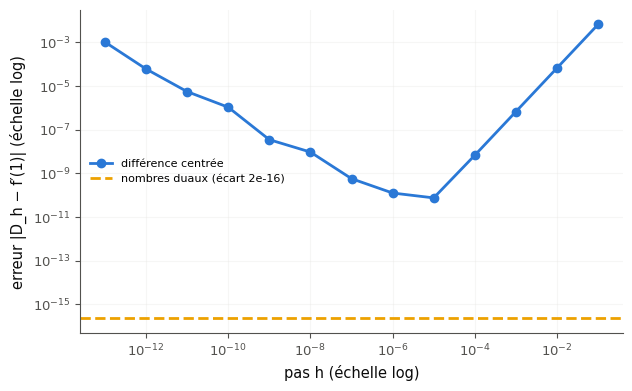

In [37]:
x_25 = sympy.Symbol("x")
exact_25 = float(sympy.diff(sympy.exp(sympy.sin(x_25)), x_25).subs(x_25, 1).evalf(30))
errors_25 = [abs((f_25(X0_25 + h) - f_25(X0_25 - h)) / (2 * h) - exact_25) for h in STEPS_25]
best_25 = int(np.argmin(errors_25))
answer_M18_25a = best_25 + 1                                   # STEPS_25[0] is 10^-1
answer_M18_25b = math.floor(math.log10(errors_25[best_25]))
answer_M18_25c, answer_M18_25d = 2, -1                         # read on the figure below
dual_25 = mymath.autodiff.dual_derivative(f_dual_25, X0_25)[1]
answer_M18_25e = bool(abs(dual_25 - exact_25) < 1e-14)
print("f′(1) =", exact_25)
print("erreurs :", [f"{e:.1e}" for e in errors_25])
print("a)", answer_M18_25a, " b)", answer_M18_25b, f"(meilleure erreur {errors_25[best_25]:.2e})", " e)",
      answer_M18_25e, f"(écart de la dérivée duale : {abs(dual_25 - exact_25):.1e})")
slopes_25 = np.diff(np.log10(errors_25)) / np.diff(np.log10(STEPS_25))
print("pentes entre deux pas voisins :", np.round(slopes_25, 2).tolist())

fig, ax = plt.subplots(figsize=(7.0, 4.2))
try:
    ax.loglog(STEPS_25, np.maximum(np.abs(np.asarray(errors_25, dtype=float)), 1e-18), "o-", color="C0",
              label="différence centrée")
    with wbm.attempt("M18.25"):          # the dual derivative: ⏳ while dual_derivative is not written
        if filled(exact_25):
            gap_25 = abs(mymath.autodiff.dual_derivative(f_dual_25, X0_25)[1] - float(exact_25))
            ax.axhline(max(gap_25, 1e-17), color="C3", ls="--", label=f"nombres duaux (écart {gap_25:.0e})")
    ax.set_xlabel("pas h (échelle log)")
    ax.set_ylabel("erreur |D_h − f′(1)| (échelle log)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
except BaseException:
    plt.close(fig)
    raise
plt.show()

In [38]:
x_25r = sympy.Symbol("x")
exact_25r = float(sympy.diff(sympy.exp(sympy.sin(x_25r)), x_25r).subs(x_25r, 1).evalf(30))
errors_25r = [abs((math.exp(math.sin(1 + h)) - math.exp(math.sin(1 - h))) / (2 * h) - exact_25r)
              for h in [10.0 ** -k for k in range(1, 14)]]
best_25r = int(np.argmin(errors_25r))
wbm.record("M18.25a", best_25r + 1,
           mistakes={"np.argmin rend un INDICE, qui part de 0, alors que la liste des pas commence à h = 10⁻¹":
                         best_25r,
                     "cherche la PLUS PETITE erreur (np.argmin), pas la plus grande": int(np.argmax(errors_25r)) + 1})
wbm.record("M18.25b", math.floor(math.log10(errors_25r[best_25r])),
           mistakes={"entre 10^m et 10^(m+1) : la partie entière de log₁₀ de l'erreur, vers le bas (math.floor), pas "
                     "son arrondi": round(math.log10(errors_25r[best_25r]))})
wbm.record("M18.25c", 2,
           mistakes={"l'erreur de troncature d'une différence CENTRÉE est d'un ordre plus élevé que celle d'une "
                     "différence avant (M05a)": 1,
                     "à droite, l'erreur diminue avec h : la courbe y monte quand on va vers la droite": -2})
wbm.record("M18.25d", -1,
           mistakes={"à gauche, l'erreur GRANDIT quand h diminue : la pente y est négative": 1,
                     "les arrondis de f(1 ± h), de taille fixe, sont divisés par 2h, pas par h²": -2})
wbm.record("M18.25e", bool(abs(math.cos(1.0) * math.exp(math.sin(1.0)) - exact_25r) < 1e-14),
           mistakes={"compare la partie en ε de f_dual_25(Dual(1.0, 1.0)) à la dérivée exacte de SymPy, en valeur "
                     "absolue": False})

WBM_ANSWER {"hash": "9f9c085f2dd8fd617ce42dfa7233a4fca29d933490ea12a10575102f86db3964", "id": "M18.25a", "kind": "int", "magnitude": 0, "mistakes": {"9da4c790ddd8f46fe57cf2b2bb505612097c02623c636427fef9c49c236e4972": "cherche la PLUS PETITE erreur (np.argmin), pas la plus grande", "ba59fe2548594cd82db1e99a23bb92ed5e0c5dfc11380500e167b5acbae1500e": "np.argmin rend un INDICE, qui part de 0, alors que la liste des pas commence à h = 10⁻¹"}, "sign": 1}
📝 Ex M18.25a : réponse enregistrée (int).
WBM_ANSWER {"hash": "56bf9f16be516ed2da891117ccd20694385cb0350daad94f29b95ba18a2adb48", "id": "M18.25b", "kind": "int", "magnitude": 1, "mistakes": {"49c887e1c013d12b65faf9a0b35e95bc2b2488f375dff05b5c2377db94e010f3": "entre 10^m et 10^(m+1) : la partie entière de log₁₀ de l'erreur, vers le bas (math.floor), pas son arrondi"}, "sign": -1}
📝 Ex M18.25b : réponse enregistrée (int).
WBM_ANSWER {"hash": "1b21df87f41f7b932ff446a215adae11d616c850f3e6e6c89ab61bc6d28d54a0", "id": "M18.25c", "kind": "int", "ma

💡 $f'(x) = \cos x\,e^{\sin x}$, soit $f'(1) \approx 1{,}253381$. À droite, l'erreur de troncature $\approx \frac{h^2}{6}\lvert f'''(1)\rvert$ : pente 2 (6,7·10⁻³, 6,8·10⁻⁵, 6,8·10⁻⁷… en divisant $h$ par 10). À gauche, les arrondis de $f(1 \pm h)$, environ $10^{-16} \times f(1)$, divisés par $2h$ : pente $-1$, en dents de scie. a) Le meilleur pas est $h = 10^{-5}$, b) avec une erreur d'environ $7{,}5 \cdot 10^{-11}$ ($m = -11$), là où les deux termes se croisent ($h^3 \approx 3 \times 10^{-16}\lvert f\rvert / \lvert f'''\rvert$). Avec $h = 10^{-13}$, l'erreur remonte à $10^{-3}$. e) Vrai : la dérivée duale s'écarte de $f'(1)$ d'environ $2 \cdot 10^{-16}$, l'arrondi d'un seul produit, sans pas ni troncature. Elle demande une fonction écrite avec les opérations de `Dual` : un programme dont on n'a pas le code ne se dérive que par des différences finies.

## Partie C · Dessiner, déboguer, tester, défier

Fiche §1, §3, §4, §6 et §8. Le graphe de calcul d'une formule, avec ses dérivées locales et ses adjoints ; trois erreurs classiques d'un gradient et de sa vérification ; des tests de propriété pour une classe de nombres duaux ; un défi : dériver la méthode de Newton. Les vérifications de M18.26 et de M18.28 s'appuient sur la référence (`ref_autodiff`), pour ne pas dépendre de ton code.

In [39]:
ref_autodiff = wbm.load_mymath("ref", alias="mymath_ref").autodiff   # the reference: the checks of M18.26 and M18.28

### Ex M18.26 — Dessiner un graphe de calcul, avec les dérivées locales sur les arêtes et les adjoints sur les nœuds 🎨 ★ ⏱️ 20 min
**Objectif :** dessiner le graphe de calcul d'une formule avec les valeurs de la passe avant, les dérivées locales des arêtes et les adjoints de la passe arrière.  
**Prérequis :** fiche §1, §2 et §4 · **Parcours :** C

Dessine le graphe de calcul de la résistance équivalente de deux résistances montées en parallèle (M18.Q1), $R = \frac{r_1r_2}{r_1 + r_2}$, calculée par $u_1 = r_1r_2$, $u_2 = r_1 + r_2$, $R = \frac{u_1}{u_2}$, en $(r_1, r_2) = (3, 6)$ (en ohms) : les valeurs de la passe avant dans les nœuds, la **dérivée locale** $\frac{\partial w}{\partial u}$ sur chaque arête $u \to w$, et l'**adjoint** $\bar{u} = \frac{\partial R}{\partial u}$ à côté de chaque nœud (fiche §1, §2 et §4 ; comme la figure du §1).
1. Calcule d'abord, à la main, puis range dans les trois dictionnaires de la cellule à compléter : les 5 valeurs (`VALUES_26`), les 6 dérivées locales (`LOCAL_26`, une par arête de `EDGES_26`) et les 5 adjoints (`ADJOINTS_26`, en partant de $\bar{R} = 1$, dans l'ordre inverse du calcul). Des nombres, ou des calculs comme `4 / 9`.
2. Écris `draw_graph(ax, positions, values, local, adjoints)`, qui dessine dans l'axe `ax` (sans en ouvrir d'autre) :
   - chaque nœud à sa position (`positions`, ici `POSITIONS_26`), avec son nom et sa valeur : `ax.text(x, y, ..., ha="center", va="center", bbox=dict(boxstyle="round", facecolor="white"))` ;
   - chaque arête $u \to w$ comme une flèche **de $u$ vers $w$** : `ax.annotate("", xy=positions[w], xytext=positions[u], arrowprops=dict(arrowstyle="->", shrinkA=22, shrinkB=22))` (la pointe en `xy`, le départ en `xytext` ; `shrinkA` et `shrinkB` raccourcissent la flèche, en points, pour qu'elle ne cache pas les nœuds) ;
   - la dérivée locale de chaque arête à la position `EDGE_LABELS_26[(u, w)]`, et l'adjoint de chaque nœud à la position `ADJOINT_LABELS_26[node]` (cellule fournie) : les nombres en clair, `0.444` ou `4/9` ;
   - des axes cachés (`ax.set_axis_off()`) et des limites qui montrent tout (`ax.set_xlim`, `ax.set_ylim`).

La vérification compare tes nombres à ceux de la référence (chacun est une dérivée, qu'elle calcule avec ses nombres duaux), puis appelle ta fonction et regarde le dessin : les six flèches, dans le bon sens, et un texte qui porte le bon nombre à chacune des positions données.

In [40]:
NODES_26 = ["r1", "r2", "u1", "u2", "R"]
EDGES_26 = [("r1", "u1"), ("r2", "u1"), ("r1", "u2"), ("r2", "u2"), ("u1", "R"), ("u2", "R")]   # u → w: w uses u
POSITIONS_26 = {"r1": (0.0, 1.0), "r2": (0.0, -1.0), "u1": (2.5, 1.0), "u2": (2.5, -1.0), "R": (5.0, 0.0)}
EDGE_LABELS_26 = {("r1", "u1"): (1.25, 1.22), ("r2", "u1"): (0.75, -0.4), ("r1", "u2"): (0.75, 0.4),
                  ("r2", "u2"): (1.25, -1.22), ("u1", "R"): (3.75, 0.74), ("u2", "R"): (3.75, -0.74)}
ADJOINT_LABELS_26 = {"r1": (0.0, 1.5), "r2": (0.0, -1.5), "u1": (2.5, 1.5), "u2": (2.5, -1.5), "R": (5.0, -0.5)}

adjoints : {'R': '1', 'u2': '-2/9', 'u1': '1/9', 'r2': '1/9', 'r1': '4/9'}
3 r̄₁ + 6 r̄₂ = 2.0 ; R = 2.0
✅ Ex M18.26 : les valeurs [r1, r2, u1, u2, R] : [3.0, 6.0, 18.0, 9.0, 2.0], comme attendu.
✅ Ex M18.26 : les dérivées locales, dans l'ordre de EDGES_26 : [6.0, 3.0, 1.0, 1.0, 0.11111111, -0.22222222], comme attendu.
✅ Ex M18.26 : les adjoints [r1, r2, u1, u2, R] : [0.44444444, 0.11111111, 0.11111111, -0.22222222, 1.0], comme attendu.
✅ draw_graph dessine dans l'axe reçu
✅ les six flèches vont de u vers w
✅ les valeurs des nœuds sont à leur place
✅ les dérivées locales sont à leur place
✅ les adjoints sont à leur place


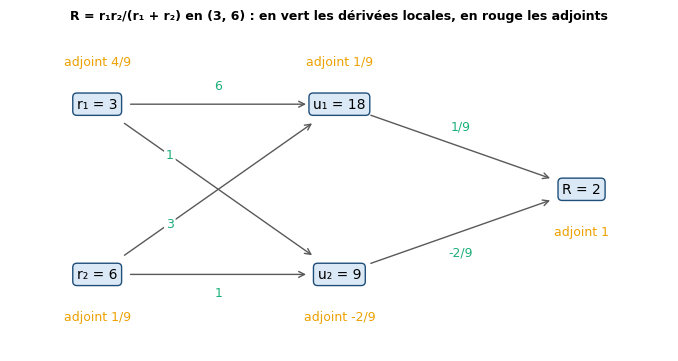

✅ Ex M18.26 : les nombres sont justes et le graphe est dessiné : nœuds, flèches, dérivées locales et adjoints.


In [41]:
from fractions import Fraction

VALUES_26 = {"r1": 3.0, "r2": 6.0, "u1": 3.0 * 6.0, "u2": 3.0 + 6.0, "R": 18.0 / 9.0}
LOCAL_26 = {("r1", "u1"): 6.0, ("r2", "u1"): 3.0,          # u1 = r1 · r2
            ("r1", "u2"): 1.0, ("r2", "u2"): 1.0,          # u2 = r1 + r2
            ("u1", "R"): 1 / 9, ("u2", "R"): -18 / 81}     # R = u1 / u2: 1/u2 and −u1/u2²
ADJOINTS_26 = {"R": 1.0}                                 # in the reverse order of the computation
ADJOINTS_26["u2"] = ADJOINTS_26["R"] * LOCAL_26[("u2", "R")]
ADJOINTS_26["u1"] = ADJOINTS_26["R"] * LOCAL_26[("u1", "R")]
ADJOINTS_26["r2"] = ADJOINTS_26["u1"] * LOCAL_26[("r2", "u1")] + ADJOINTS_26["u2"] * LOCAL_26[("r2", "u2")]
ADJOINTS_26["r1"] = ADJOINTS_26["u1"] * LOCAL_26[("r1", "u1")] + ADJOINTS_26["u2"] * LOCAL_26[("r1", "u2")]


def draw_graph(ax, positions, values, local, adjoints):
    """In ax (and no other axes): each node at its position with its name and value, each edge u → w as an arrow
    (ax.annotate) with its local derivative at EDGE_LABELS_26[(u, w)], each adjoint at ADJOINT_LABELS_26[node]."""
    names = {"r1": "r₁", "r2": "r₂", "u1": "u₁", "u2": "u₂", "R": "R"}

    def shown(x):
        return str(Fraction(x).limit_denominator(100))         # 4/9 rather than 0.4444

    for (u, w), derivative in local.items():
        ax.annotate("", xy=positions[w], xytext=positions[u],
                    arrowprops=dict(arrowstyle="->", color="0.35", shrinkA=24, shrinkB=24))
        ax.text(*EDGE_LABELS_26[(u, w)], shown(derivative), ha="center", va="center", fontsize=9, color="C2",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none"))
    for node, (x, y) in positions.items():
        ax.text(x, y, f"{names[node]} = {shown(values[node])}", ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round", facecolor="#dbe9f6", edgecolor="#1f4e79"))
        ax.text(*ADJOINT_LABELS_26[node], f"adjoint {shown(adjoints[node])}", ha="center", va="center", fontsize=9,
                color="C3")
    ax.set_xlim(-0.9, 5.9)
    ax.set_ylim(-1.9, 1.9)
    ax.set_axis_off()
    ax.set_title("R = r₁r₂/(r₁ + r₂) en (3, 6) : en vert les dérivées locales, en rouge les adjoints", fontsize=9)


print("adjoints :", {k: str(Fraction(v).limit_denominator(100)) for k, v in ADJOINTS_26.items()})
print("3 r̄₁ + 6 r̄₂ =", 3 * ADJOINTS_26["r1"] + 6 * ADJOINTS_26["r2"], "; R =", VALUES_26["R"])


with checked("M18.26"):
    results_26 = []

    def report_26(ok, success, failure):
        results_26.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    if not filled(*VALUES_26.values(), *LOCAL_26.values(), *ADJOINTS_26.values()):
        print("⏳ Ex M18.26 : pas encore fait (remplis les trois dictionnaires).")
        raise StopCheck
    dd_26 = ref_autodiff.dual_derivative                      # each number as a derivative, by the reference
    r1_26, r2_26 = 3.0, 6.0
    u1_26, u2_26 = r1_26 * r2_26, r1_26 + r2_26
    want_values_26 = [r1_26, r2_26, u1_26, u2_26, u1_26 / u2_26]
    want_local_26 = [dd_26(lambda t: t * r2_26, r1_26)[1], dd_26(lambda t: r1_26 * t, r2_26)[1],
                     dd_26(lambda t: t + r2_26, r1_26)[1], dd_26(lambda t: r1_26 + t, r2_26)[1],
                     dd_26(lambda t: t / u2_26, u1_26)[1], dd_26(lambda t: u1_26 / t, u2_26)[1]]
    want_adjoints_26 = [dd_26(lambda t: t * r2_26 / (t + r2_26), r1_26)[1],
                        dd_26(lambda t: r1_26 * t / (r1_26 + t), r2_26)[1],
                        dd_26(lambda t: t / u2_26, u1_26)[1], dd_26(lambda t: u1_26 / t, u2_26)[1], 1.0]
    results_26.append(same("M18.26", "les valeurs [r1, r2, u1, u2, R]", [VALUES_26[k] for k in NODES_26],
                           want_values_26))
    results_26.append(same("M18.26", "les dérivées locales, dans l'ordre de EDGES_26",
                           [LOCAL_26[e] for e in EDGES_26], want_local_26))
    results_26.append(same("M18.26", "les adjoints [r1, r2, u1, u2, R]", [ADJOINTS_26[k] for k in NODES_26],
                           want_adjoints_26))

    def node_at_26(point):
        """The node whose position is within 0.6 of point, or None."""
        best = min(NODES_26, key=lambda k: math.dist(POSITIONS_26[k], point))
        return best if math.dist(POSITIONS_26[best], point) < 0.6 else None

    def numbers_26(text):
        """The numbers written in a text: 18, 0.444, 0,444, 4/9, −2/9, \\frac{4}{9}."""
        text = text.replace("−", "-").replace(",", ".")
        text = re.sub(r"\\d?frac\{(-?\d+)\}\{(\d+)\}", r"\1/\2", text)
        return [float(a) / float(b) if b else float(a)
                for a, b in re.findall(r"(-?\d+(?:\.\d+)?)(?:\s*/\s*(\d+(?:\.\d+)?))?", text)
                if not b or float(b) != 0]

    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    try:
        opened_26 = drawn(draw_graph, ax, dict(POSITIONS_26), dict(VALUES_26), dict(LOCAL_26), dict(ADJOINTS_26))
        report_26(not opened_26, "draw_graph dessine dans l'axe reçu",
                  "draw_graph doit dessiner dans l'axe reçu, sans ouvrir de figure (ni plt.figure ni plt.subplots)")
        arrows_26, texts_26 = set(), []
        for item in ax.texts:
            if isinstance(item, Annotation):
                if item.arrow_patch is not None and item.xycoords == "data" and item.anncoords == "data":
                    arrows_26.add((node_at_26(item.xyann), node_at_26(item.xy)))       # (start, head)
                if item.get_text().strip() and item.anncoords == "data":
                    texts_26.append((tuple(item.xyann), item.get_text()))
            elif item.get_text().strip() and item.get_transform() == ax.transData:
                texts_26.append((tuple(item.get_position()), item.get_text()))
        missing_26 = [f"{u} → {w}" for u, w in EDGES_26 if (u, w) not in arrows_26]
        backwards_26 = [f"{u} → {w}" for u, w in EDGES_26 if (u, w) not in arrows_26 and (w, u) in arrows_26]
        report_26(not missing_26, "les six flèches vont de u vers w",
                  f"il manque la flèche de {len(missing_26)} arête(s) : {', '.join(missing_26)}"
                  + (f" (dans le mauvais sens : {', '.join(backwards_26)} ; la pointe est en xy, le départ en "
                     f"xytext)" if backwards_26 else " (ax.annotate, la pointe en xy, le départ en xytext, en "
                     "coordonnées des données)"))

        def shown_26(point, value):
            near = [text for where, text in texts_26 if math.dist(where, point) < 0.3]
            return any(abs(x - value) <= max(0.01, 0.01 * abs(value)) for text in near for x in numbers_26(text))

        for kind_26, places_26, wanted_26 in (
                ("les valeurs des nœuds", [POSITIONS_26[k] for k in NODES_26], want_values_26),
                ("les dérivées locales", [EDGE_LABELS_26[e] for e in EDGES_26], want_local_26),
                ("les adjoints", [ADJOINT_LABELS_26[k] for k in NODES_26], want_adjoints_26)):
            absent_26 = [f"{tuple(round(c, 2) for c in p)}" for p, v in zip(places_26, wanted_26) if not shown_26(p, v)]
            report_26(not absent_26, f"{kind_26} sont à leur place",
                      f"{kind_26} : aucun texte qui porte le bon nombre, en clair (0.444 ou 4/9), aux positions "
                      f"{', '.join(absent_26[:3])}" + (" …" if len(absent_26) > 3 else ""))
    except BaseException:
        plt.close(fig)
        raise
    plt.show()
    verdict("M18.26", all(results_26), "les nombres sont justes et le graphe est dessiné : nœuds, flèches, dérivées "
                                       "locales et adjoints.", "relis les lignes ❌ ci-dessus.")

**Regarde ta figure**, puis, dans ta copie : quels nœuds reçoivent deux contributions dans la passe arrière, et lesquelles ? Retrouve $\bar{r}_1$ et $\bar{r}_2$ en dérivant $R$ directement. Que vaut $3\bar{r}_1 + 6\bar{r}_2$, et pourquoi (que devient $R$ quand on multiplie $r_1$ et $r_2$ par un même nombre) ? Laquelle des deux résistances faut-il changer pour faire bouger $R$ le plus ?

💡 Valeurs : $u_1 = 18$, $u_2 = 9$, $R = 2$. Dérivées locales : $r_2 = 6$ et $r_1 = 3$ vers $u_1$, 1 et 1 vers $u_2$, $\frac{1}{u_2} = \frac19$ et $-\frac{u_1}{u_2^2} = -\frac29$ vers $R$. Adjoints : $\bar{R} = 1$, $\bar{u}_1 = \frac19$, $\bar{u}_2 = -\frac29$, puis $r_1$ et $r_2$ reçoivent chacun deux contributions : $\bar{r}_1 = \frac19 \times 6 - \frac29 = \frac49$ et $\bar{r}_2 = \frac19 \times 3 - \frac29 = \frac19$, soit $\frac{r_2^2}{(r_1 + r_2)^2}$ et $\frac{r_1^2}{(r_1 + r_2)^2}$. $3\bar{r}_1 + 6\bar{r}_2 = 2 = R$ : multiplier les deux résistances par $\lambda$ multiplie $R$ par $\lambda$, et la dérivée en $\lambda = 1$ donne $r_1\bar{r}_1 + r_2\bar{r}_2 = R$. La plus petite résistance, $r_1$, fait bouger $R$ quatre fois plus.

### Ex M18.27 — Chasse à l'erreur : un gradient transposé, un adjoint compté sur un seul chemin, un pas h trop petit 🐛 ★ ⏱️ 15 min
**Objectif :** reconnaître trois erreurs classiques du calcul et de la vérification d'un gradient qui ne lèvent aucune erreur Python, puis les corriger.  
**Prérequis :** fiche §4, §6 et §8 · **Parcours :** C, E

Un collègue a écrit trois morceaux de code (cellule fournie) ; chacun a l'erreur que nomme le titre, et aucun ne lève d'erreur Python :
1. `grad_trace(A, X)` doit rendre le gradient de $\mathbf{X} \mapsto \operatorname{tr}(\mathbf{A}\mathbf{X})$, de la forme de $\mathbf{X}$. Pour le vérifier, il a écrit `check_along(f, G, X, H, h)`, qui compare la différence centrée de $f$ le long d'une direction $\mathbf{H}$, $\frac{f(\mathbf{X} + h\mathbf{H}) - f(\mathbf{X} - h\mathbf{H})}{2h}$, à la prévision $\sum_{ij}G_{ij}H_{ij}$ (fiche §8), et rend `True` quand elles diffèrent de moins de $10^{-6}$. Il l'a appelée en `A_27` et `X_27`, le long de la direction $\mathbf{I}$ : son gradient est passé.
2. `backward_27(x, y)` rend la valeur de $f(x, y) = x\sin(xy)$ et son gradient $(\frac{\partial f}{\partial x}, \frac{\partial f}{\partial y})$, par une passe avant ($u_1 = xy$, $u_2 = \sin u_1$, $f = x\,u_2$) puis une passe arrière écrites ligne à ligne ; l'un de ses adjoints est **incomplet** : il lui manque la contribution d'un chemin.
3. Il a vérifié la formule du gradient de $f$ (`gradient_27`, qui est juste) avec `check_along` et $h = 10^{-13}$, le long de la direction $(1, -1)$ en $(1, 2)$ : sa vérification dit `False`, et il croit la formule fausse.

À faire :
- a) d'abord, à la main : le $\bar{x}$ que rend `backward_27(1.0, 2.0)` (4 décimales) ; vérifie-le en appelant la fonction ;
- (1) tire une direction `H_27` de la forme de `X_27`, avec `np.random.default_rng(5137)` (des coefficients de loi normale), vérifie qu'elle démasque `grad_trace`, puis écris `grad_trace_fixed(A, X)` ;
- (2) écris `backward_27_fixed(x, y)`, avec la même passe avant et une passe arrière juste ; b) le gradient qu'elle rend en $(1, 2)$ (une liste de 2 nombres, 4 décimales) ;
- (3) choisis le pas `STEP_27` d'une vérification fiable (fiche §8 ; M05a).

La vérification essaie tes corrections sur des cas que tu ne vois pas : d'autres matrices, carrées ou non, d'autres points, d'autres directions.

In [42]:
A_27 = np.array([[1.0, 4.0],
                 [-2.0, 0.5]])
X_27 = np.array([[1.5, 0.0],
                 [-1.0, 2.5]])


def check_along(f, G, X, H, h=1e-5):
    """Compare the central difference of f along the direction H with the prediction Σ G ⊙ H (fiche §8). Returns
    (True when they differ by less than 1e-6, the central difference, the prediction)."""
    X, H = np.asarray(X, dtype=float), np.asarray(H, dtype=float)
    numerical = (f(X + h * H) - f(X - h * H)) / (2 * h)
    predicted = float(np.sum(np.asarray(G, dtype=float) * H))
    return bool(abs(numerical - predicted) < 1e-6), float(numerical), predicted


def trace_27(X):
    """f(X) = tr(A_27 X)."""
    return float(np.trace(A_27 @ X))


def f_27(p):
    """f(x, y) = x sin(x y), for p = (x, y)."""
    return p[0] * math.sin(p[0] * p[1])


def gradient_27(p):
    """The gradient of f_27 at p by its formula, (sin(xy) + xy cos(xy), x² cos(xy)): right (checked)."""
    x, y = p
    return np.array([math.sin(x * y) + x * y * math.cos(x * y), x ** 2 * math.cos(x * y)])


# The colleague's code
def grad_trace(A, X):
    """The gradient of X ↦ tr(A X), of the shape of X."""
    return A


def backward_27(x, y):
    """f(x, y) = x sin(x y) and its gradient (∂f/∂x, ∂f/∂y), by a forward pass then a backward pass, line by line."""
    u1 = x * y                       # forward pass
    u2 = math.sin(u1)
    f = x * u2
    f_bar = 1.0                      # backward pass, in the reverse order
    u2_bar = f_bar * x               # f = x · u2: ∂f/∂u2 = x
    u1_bar = u2_bar * math.cos(u1)   # u2 = sin u1
    x_bar = u1_bar * y               # u1 = x · y: ∂u1/∂x = y
    y_bar = u1_bar * x               # ∂u1/∂y = x
    return f, x_bar, y_bar


print("(1) check_along de grad_trace le long de I :", check_along(trace_27, grad_trace(A_27, X_27), X_27, np.eye(2)))
print("(3) check_along de gradient_27 avec h = 1e-13 :",
      check_along(f_27, gradient_27((1.0, 2.0)), np.array([1.0, 2.0]), np.array([1.0, -1.0]), h=1e-13))

(1) check_along de grad_trace le long de I : (True, 1.5000000000098266, 1.5)
(3) check_along de gradient_27 avec h = 1e-13 : (False, 0.4923839114212569, 0.4931505902785393)


In [43]:
answer_M18_27a = backward_27(1.0, 2.0)[1]
H_27 = np.random.default_rng(5137).normal(size=X_27.shape)
print("(1) le long de H_27 :", check_along(trace_27, grad_trace(A_27, X_27), X_27, H_27))


def grad_trace_fixed(A, X):
    """The gradient of X ↦ tr(A X), of the shape of X."""
    return np.asarray(A, dtype=float).T                 # d tr(A X) = tr(A dX): G = Aᵀ


def backward_27_fixed(x, y):
    """f(x, y) = x sin(x y) and its gradient (∂f/∂x, ∂f/∂y), by a forward pass then a backward pass, line by line."""
    u1 = x * y                       # forward pass
    u2 = math.sin(u1)
    f = x * u2
    f_bar = 1.0                      # backward pass, in the reverse order
    u2_bar = f_bar * x               # f = x · u2: ∂f/∂u2 = x
    u1_bar = u2_bar * math.cos(u1)   # u2 = sin u1
    x_bar = f_bar * u2 + u1_bar * y  # x has two successors, f (∂f/∂x = u2) and u1 (∂u1/∂x = y): two paths
    y_bar = u1_bar * x               # ∂u1/∂y = x
    return f, x_bar, y_bar


answer_M18_27b = list(backward_27_fixed(1.0, 2.0)[1:])
STEP_27 = 1e-5
print("a)", round(answer_M18_27a, 4), " b)", np.round(answer_M18_27b, 4).tolist())
print("(3) avec h = 1e-5 :", check_along(f_27, gradient_27((1.0, 2.0)), np.array([1.0, 2.0]), np.array([1.0, -1.0]),
                                         h=STEP_27))


results_27, parts_27 = [], []


def report_27(ok, success, failure):
    results_27.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


with checked("M18.27"):                                       # (1) the direction H_27, then grad_trace_fixed
    if not filled(H_27):
        print("⏳ Ex M18.27 : (1) pas encore fait (H_27).")
        raise StopCheck
    H_c27 = np.asarray(H_27, dtype=float)
    if H_c27.shape != X_27.shape:
        print(f"❌ Ex M18.27 : (1) H_27 doit avoir la forme de X_27, {X_27.shape} ; reçu {H_c27.shape}.")
        raise StopCheck
    report_27(not np.allclose(H_c27, H_c27.T), "(1) H_27 n'est pas symétrique",
              "(1) H_27 est symétrique : le long d'une direction symétrique, G et Gᵀ prévoient la même chose (fiche §8)")
    report_27(not check_along(trace_27, grad_trace(A_27, X_27), X_27, H_c27)[0],
              "(1) le long de H_27, check_along démasque grad_trace",
              "(1) le long de H_27, check_along laisse encore passer grad_trace : tire une direction au hasard")
    rng_27 = np.random.default_rng(5138)
    wrong_27 = []
    for shape_27 in ((2, 2), (3, 3), (2, 3), (1, 4)):        # A of shape (m, n), X of shape (n, m)
        A_c27, X_c27 = rng_27.normal(size=shape_27), rng_27.normal(size=shape_27[::-1])
        got_27 = grad_trace_fixed(A_c27.copy(), X_c27.copy())
        if got_27 is None or np.shape(got_27) != X_c27.shape or not np.allclose(np.asarray(got_27, dtype=float),
                                                                                 A_c27.T):
            wrong_27.append(f"A de forme {shape_27}, X de forme {shape_27[::-1]} : attendu un gradient de la forme de X, "
                            f"{X_c27.shape}, reçu " + ("None" if got_27 is None else f"la forme {np.shape(got_27)}"
                                                       if np.shape(got_27) != X_c27.shape else "d'autres nombres"))
    report_27(not wrong_27, "(1) grad_trace_fixed : quatre matrices A, carrées ou non", "(1) grad_trace_fixed, "
              + " ; ".join(wrong_27[:2]))
    parts_27.append(1)

with checked("M18.27"):                                       # (2) backward_27_fixed
    wrong_27 = []
    for point_27 in [(1.0, 2.0), *np.random.default_rng(5139).normal(size=(4, 2)).tolist()]:
        got_27 = backward_27_fixed(*point_27)
        want_27 = [f_27(point_27), *gradient_27(point_27)]
        if not (isinstance(got_27, tuple) and len(got_27) == 3 and np.allclose(np.asarray(got_27, dtype=float),
                                                                                want_27)):
            wrong_27.append(f"en {np.round(point_27, 3).tolist()} : attendu {np.round(want_27, 4).tolist()}, reçu "
                            f"{got_27!r}"[:160])
    report_27(not wrong_27, "(2) backward_27_fixed : la valeur et le gradient en cinq points",
              "(2) backward_27_fixed, " + " ; ".join(wrong_27[:2]))
    parts_27.append(2)

with checked("M18.27"):                                       # (3) the step of a reliable check
    if not filled(STEP_27):
        print("⏳ Ex M18.27 : (3) pas encore fait (STEP_27).")
        raise StopCheck
    rng_27 = np.random.default_rng(5139)
    cases_27 = [(np.array([1.0, 2.0]), np.array([1.0, -1.0]))] + [(rng_27.normal(size=2), rng_27.normal(size=2))
                                                                 for _ in range(4)]
    refused_27 = [p for p, d in cases_27 if not check_along(f_27, gradient_27(p), p, d, h=float(STEP_27))[0]]
    report_27(not refused_27, f"(3) avec h = {float(STEP_27):g}, la vérification accepte le gradient juste en cinq "
                              f"points", f"(3) avec h = {float(STEP_27):g}, la vérification refuse encore le gradient "
                              f"juste en {len(refused_27)} point(s) sur 5 : un pas trop petit (les arrondis) ou trop "
                              f"grand (la troncature)")
    caught_27 = [p for p, d in cases_27 if not check_along(f_27, np.array(backward_27(*p)[1:]), p, d,
                                                           h=float(STEP_27))[0]]
    report_27(len(caught_27) == len(cases_27), "(3) et elle démasque la passe du collègue, en cinq points",
              f"(3) avec ce pas, la vérification laisse passer la passe fausse du collègue en "
              f"{len(cases_27) - len(caught_27)} point(s)")
    parts_27.append(3)

if len(parts_27) == 3:
    verdict("M18.27", all(results_27), "la direction, les deux fonctions corrigées et le pas passent tous les cas.",
            "relis les lignes ❌ ci-dessus.")

(1) le long de H_27 : (False, 5.91307815305253, -3.556509091531096)
a) -0.8323  b) [0.077, -0.4161]
(3) avec h = 1e-5 : (True, 0.4931505903749133, 0.4931505902785393)
✅ (1) H_27 n'est pas symétrique
✅ (1) le long de H_27, check_along démasque grad_trace
✅ (1) grad_trace_fixed : quatre matrices A, carrées ou non
✅ (2) backward_27_fixed : la valeur et le gradient en cinq points
✅ (3) avec h = 1e-05, la vérification accepte le gradient juste en cinq points
✅ (3) et elle démasque la passe du collègue, en cinq points
✅ Ex M18.27 : la direction, les deux fonctions corrigées et le pas passent tous les cas.


In [44]:
wbm.record("M18.27a", 2 * math.cos(2.0), decimals=4,
           mistakes={"a) demande ce que RENVOIE la passe du collègue : refais-la ligne à ligne, telle qu'elle est écrite":
                         math.sin(2.0) + 2 * math.cos(2.0),
                     "relis la ligne qui calcule x_bar : par quel chemin passe le seul terme qu'elle garde ?":
                         math.sin(2.0)})
wbm.record("M18.27b", [math.sin(2.0) + 2 * math.cos(2.0), math.cos(2.0)], decimals=4,
           mistakes={"x a deux successeurs, u₁ = xy et f = x u₂ : son adjoint est la somme de leurs deux contributions ; "
                     "un chemin est oublié": [2 * math.cos(2.0), math.cos(2.0)],
                     "la contribution de u₁ = xy à x̄ compte aussi : ū₁ × y": [math.sin(2.0), math.cos(2.0)]})

WBM_ANSWER {"coarse_any": {"0": ["a40c1711d54b17c0b606123c2d3f80580eb0205e0a8d416f9837a3766e0129d7"], "1": ["a3017db2b23dab22e6616e6b7a66eba560c07846b7be757404adf02a9e25c8db"]}, "coarser": {"2": ["d677511ea33b9c34617cc487be9385c7fe4e9c6ec1e65a3df461863f77411ec8"]}, "decimals": 4, "hash": "ebc795349fa8e309f3d77a17968f12044e426de462a589b9fe60d481023fd76b", "hash_coarse": "69645f957f89a3551358ec0d8eb7ecd241e1395e90c1836fcfcfa0c3d6ab0edf", "id": "M18.27a", "kind": "float", "magnitude": -1, "mistakes": {"5cf10ba470f3ebde54515cb5597d7c342f6973a7ac17e2335ba25004d1d1e7c7": "a) demande ce que RENVOIE la passe du collègue : refais-la ligne à ligne, telle qu'elle est écrite", "b8789c53a6b28946b1d668560f1a8d804ae0b7f37bfb775799be5bdf3551fdf6": "relis la ligne qui calcule x_bar : par quel chemin passe le seul terme qu'elle garde ?"}, "sign": -1}
📝 Ex M18.27a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 4, "element_coarse": [["30a0a0a65012057a5c2ed268f7597f1700a5ab8a47c929e4ec

**Après la vérification**, dans ta copie : pourquoi la direction $\mathbf{I}$ ne pouvait-elle pas voir l'erreur de `grad_trace` (que vaut $\sum_{ij}G_{ij}I_{ij}$, pour $\mathbf{G}$ et pour $\mathbf{G}^\top$) ? Pour quelles matrices $\mathbf{A}$ `grad_trace` aurait-elle raison ? Dans `backward_27`, quel chemin de $x$ vers $f$ l'adjoint incomplet oublie-t-il ? Avec $h = 10^{-13}$, de quel ordre est l'erreur d'arrondi de la différence centrée (fiche §8, M05a), et pourquoi dépasse-t-elle $10^{-6}$ ?

💡 a) L'adjoint du collègue est incomplet : il ne garde que le chemin $x \to u_1 \to u_2 \to f$, $\bar{x} = \bar{u}_1y = xy\cos(xy) = 2\cos 2 \approx -0{,}8323$ ; le chemin direct $x \to f$ (le facteur $x$ de $f = x\,u_2$), qui apporte $\bar{f}\,u_2 = \sin 2$, est oublié. b) Avec les deux chemins, $\bar{x} = \sin(xy) + xy\cos(xy) = \sin 2 + 2\cos 2 \approx 0{,}0770$ et $\bar{y} = x^2\cos(xy) = \cos 2 \approx -0{,}4161$. (1) Le long de $\mathbf{I}$, la prévision est $\operatorname{tr}\mathbf{G} = \operatorname{tr}\mathbf{G}^\top$ : $\mathbf{A}$ et $\mathbf{A}^\top$ passent toutes deux ; une direction gaussienne voit l'écart $\sum_{ij}(\mathbf{A} - \mathbf{A}^\top)_{ij}H_{ij} = 6(H_{12} - H_{21})$. `grad_trace` n'aurait raison que pour $\mathbf{A}$ symétrique. (3) Avec $h = 10^{-13}$, les arrondis de $f(\mathbf{X} \pm h\mathbf{H})$, de l'ordre de $10^{-16}$, divisés par $2h$, font une erreur de l'ordre de $10^{-3}$ ; avec $h = 10^{-5}$, l'erreur tombe vers $10^{-10}$.

### Ex M18.28 — Tester une classe par ses propriétés : distributivité et dérivées connues des nombres duaux 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire des tests de propriété pour une classe de nombres duaux, et s'assurer qu'ils attrapent deux classes fausses.  
**Prérequis :** fiche §3 ; Ex M18.20 ; M17.22 · **Parcours :** C

Un **test de propriété** vérifie une loi que tout résultat juste respecte, sans connaître la réponse de chaque cas (M17.22). Écris deux fonctions de test dans le style de pytest (des `assert` avec un message qui dit le cas), qui reçoivent une **classe** de nombres duaux `Dual`, de même contrat que la tienne :
- `test_distributivity(Dual)` : avec un générateur de graine 5136 (`np.random.default_rng(5136)`, créé dans le test), tire au moins 20 triplets de duaux $u$, $v$, $w$ (valeurs et dérivées de loi normale), et vérifie $u(v + w) = uv + uw$, valeur **et** dérivée (`math.isclose(..., rel_tol=1e-9, abs_tol=1e-12)`), en calculant $u(v + w)$ d'abord ;
- `test_known_derivatives(Dual)` : en quelques points $t > 0$ (au moins trois), la dérivée calculée avec `Dual(t, 1.0)` de $\sin^2 t + \cos^2 t$ est nulle, celle de $e^{\ln t}$ vaut 1, et celle de $t^p$ vaut $p\,t^{p-1}$ pour quelques exposants $p$ (entiers, négatif, fractionnaire). Écris les carrés comme des **produits** (`s * s`, avec `s = t.sin()`) : le test doit passer par la multiplication.

La cellule fournie donne deux classes **fausses**, construites sur la référence : `BrokenDual`, dont le produit suit une règle fausse, et `AliasingDual`, dont le produit modifie son opérande de gauche au lieu de rendre un nouveau `Dual` (une erreur classique d'une classe Python). La vérification lance tes deux tests sur le `Dual` de la référence, où ils doivent **passer** ; sur `BrokenDual` et sur `AliasingDual`, où au moins un test doit **échouer** pour chacune, par un `assert` et pas par une autre erreur ; puis sur **ton** `Dual`.

In [45]:
RefDual = ref_autodiff.Dual


class BrokenDual(RefDual):
    """A Dual whose product follows a wrong rule; every other operation is the reference's, and keeps the class."""

    def __mul__(self, other):
        o = other if isinstance(other, RefDual) else RefDual(other, 0.0)
        return BrokenDual(self.value * o.value, self.derivative * o.derivative)

    __rmul__ = __mul__


class AliasingDual(RefDual):
    """A Dual whose product changes its left operand in place and returns it, instead of a new Dual; every other
    operation is the reference's, and keeps the class."""

    def __mul__(self, other):
        o = other if isinstance(other, RefDual) else RefDual(other, 0.0)
        self.value, self.derivative = self.value * o.value, self.value * o.derivative + self.derivative * o.value
        return self

    __rmul__ = __mul__


def _keeping_class(name):
    """The method `name` of the reference, run on a plain copy of self, its result turned back into the class."""
    method = getattr(RefDual, name)

    def wrapper(self, *args):
        result = method(RefDual(self.value, self.derivative), *args)
        return type(self)(result.value, result.derivative) if isinstance(result, RefDual) else result
    return wrapper


for _cls in (BrokenDual, AliasingDual):
    for _name in ("__add__", "__radd__", "__sub__", "__rsub__", "__neg__", "__truediv__", "__rtruediv__", "__pow__",
                  "exp", "log", "sin", "cos"):
        setattr(_cls, _name, _keeping_class(_name))

In [46]:
def test_distributivity(Dual):
    """u (v + w) = u v + u w, value and derivative, for at least 20 triples of duals drawn with the seed 5136."""
    rng = np.random.default_rng(5136)
    for case in range(25):
        u, v, w = (Dual(*rng.normal(size=2)) for _ in range(3))
        left = u * (v + w)
        right = u * v + u * w
        for part in ("value", "derivative"):
            a, b = getattr(left, part), getattr(right, part)
            assert math.isclose(a, b, rel_tol=1e-9, abs_tol=1e-12), (
                f"case {case}: the {part} of u (v + w) is {a!r}, that of u v + u w is {b!r}")


def test_known_derivatives(Dual):
    """At a few points t > 0: (sin²t + cos²t)′ = 0 (squares written as products), (e^(ln t))′ = 1 and
    (t^p)′ = p t^(p − 1) for a few exponents p."""
    for t in (0.3, 1.0, 2.7):
        x = Dual(t, 1.0)
        s, c = x.sin(), x.cos()
        one = s * s + c * c
        assert math.isclose(one.derivative, 0.0, abs_tol=1e-12), (
            f"t = {t}: the derivative of sin² + cos² is {one.derivative!r}, expected 0")
        identity = x.log().exp()
        assert math.isclose(identity.derivative, 1.0, rel_tol=1e-12), (
            f"t = {t}: the derivative of exp(log t) is {identity.derivative!r}, expected 1")
        for p in (2, 3, -1, 0.5, 2.5):
            power = x ** p
            assert math.isclose(power.derivative, p * t ** (p - 1), rel_tol=1e-12), (
                f"t = {t}, p = {p}: the derivative of t ** p is {power.derivative!r}, expected {p * t ** (p - 1)!r}")


for label_28s, cls_28s in (("BrokenDual", BrokenDual), ("AliasingDual", AliasingDual)):
    for name_28s, test_28s in (("distributivité", test_distributivity), ("dérivées connues", test_known_derivatives)):
        try:
            test_28s(cls_28s)
            print(f"{label_28s}, {name_28s} : pas attrapée")
        except AssertionError as exc:
            print(f"{label_28s}, {name_28s} :", exc)


def outcome_28(test, cls):
    """"" when test(cls) passes; "assert : …" when an assert fails; "erreur …" for another error (⏳ goes through)."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            test(cls)
        return ""
    except NotImplementedError:
        raise
    except AssertionError as exc:
        return "assert : " + (str(exc)[:140] or "un assert sans message")
    except Exception as exc:  # noqa: BLE001 - a crash is not a failed assert
        return f"erreur {type(exc).__name__} : {str(exc)[:120]}"


tests_28 = {"test_distributivity": test_distributivity, "test_known_derivatives": test_known_derivatives}
with checked("M18.28"):
    for name_28, test_28 in tests_28.items():
        if len(inspect.signature(test_28).parameters) != 1:
            raise TypeError(f"{name_28} prend un seul argument, la classe à tester : def {name_28}(Dual)")
    results_28 = []

    def report_28(ok, success, failure):
        results_28.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    for name_28, test_28 in tests_28.items():
        why_28 = outcome_28(test_28, ref_autodiff.Dual)
        report_28(not why_28, f"{name_28} passe sur le Dual de la référence",
                  f"{name_28} échoue sur le Dual de la référence, une classe juste : c'est le test qui est faux "
                  f"({why_28})")
    hints_28 = {"BrokenDual": "écris les carrés de sin² + cos² comme des produits (s * s), pas avec **",
                "AliasingDual": "dans la distributivité, calcule u * (v + w) d'abord, puis u * v + u * w avec les "
                                "MÊMES objets u, v, w"}
    for label_28, cls_28 in (("BrokenDual", BrokenDual), ("AliasingDual", AliasingDual)):
        outcomes_28 = {name: outcome_28(test, cls_28) for name, test in tests_28.items()}
        caught_28 = [name for name, why in outcomes_28.items() if why.startswith("assert")]
        crashed_28 = [f"{name} ({why})" for name, why in outcomes_28.items() if why.startswith("erreur")]
        report_28(caught_28 and not crashed_28, f"{label_28} est attrapée par {', '.join(caught_28)}",
                  f"{label_28} : " + (f"un test plante au lieu d'échouer sur un assert : {'; '.join(crashed_28)}"
                                      if crashed_28 else f"aucun de tes tests ne la voit ; {hints_28[label_28]}"))
    verdict("M18.28", all(results_28), "tes deux tests passent sur une classe juste et attrapent les deux classes "
                                       "fausses.", "relis les lignes ❌ ci-dessus.")

with checked("M18.28"):                                      # your own Dual
    for name_28, test_28 in tests_28.items():
        why_28 = outcome_28(test_28, mymath.autodiff.Dual)
        print(f"✅ {name_28} passe sur ton Dual" if not why_28 else
              f"❌ {name_28} échoue sur ton Dual ({why_28}) : si tes tests passent sur la référence, l'erreur est dans "
              f"ta classe (lance aussi les tests de M18.20)")

BrokenDual, distributivité : pas attrapée
BrokenDual, dérivées connues : t = 0.3: the derivative of sin² + cos² is 1.0, expected 0
AliasingDual, distributivité : case 0: the value of u (v + w) is -0.02480603152588939, that of u v + u w is -0.04961206305177878
AliasingDual, dérivées connues : pas attrapée
✅ test_distributivity passe sur le Dual de la référence
✅ test_known_derivatives passe sur le Dual de la référence
✅ BrokenDual est attrapée par test_known_derivatives
✅ AliasingDual est attrapée par test_distributivity
✅ Ex M18.28 : tes deux tests passent sur une classe juste et attrapent les deux classes fausses.
✅ test_distributivity passe sur ton Dual
✅ test_known_derivatives passe sur ton Dual


**Après la vérification**, dans ta copie : lequel de tes tests attrape chaque classe fausse, et pourquoi l'autre ne la voit pas ? Montre que toute règle du produit de la forme $(a + b\varepsilon)(c + d\varepsilon) = ac + (\alpha\,ad + \beta\,bc + \gamma\,bd)\,\varepsilon$, quels que soient $\alpha$, $\beta$, $\gamma$, respecte la distributivité : qu'est-ce que ce test vérifie vraiment ? Une classe fausse pourrait-elle passer tes deux tests ? Cherche une erreur qui touche `sin` et `cos` à la fois et garde $\sin^2 + \cos^2$ constant. Que verraient alors les tests de `mymath`, qui comparent à SymPy ?

💡 `BrokenDual` multiplie les dérivées, $(uv)' = u'v'$ (une erreur classique) : $\sin t \cdot \sin t$ a alors la dérivée $\cos^2 t$ et $\cos t \cdot \cos t$ la dérivée $\sin^2 t$, d'où une somme de dérivée 1 au lieu de 0 ; écrit avec `** 2`, le test ne passerait pas par le produit et ne verrait rien. La distributivité ne la voit pas : toute règle **bilinéaire** en $(a, b)$ et $(c, d)$ la respecte. `AliasingDual` calcule le bon produit, mais modifie $u$ : dans $u(v + w)$ puis $uv + uw$, le second calcul part d'un $u$ changé, et la distributivité casse ; les dérivées connues, qui n'utilisent pas une valeur après l'avoir multipliée, ne voient rien. Une classe dont `sin` et `cos` doubleraient toutes deux leur dérivée passerait les deux tests (les deux termes de $(\sin^2 + \cos^2)'$ doublent et s'annulent encore) : les tests de `mymath`, qui comparent chaque fonction à SymPy, l'attrapent.

### Ex M18.29 — Défi : dériver une boucle, la méthode de Newton pour √a, en mode direct 🏆 ★★★ ⏱️ 30 min
**Objectif :** dériver un algorithme itératif en faisant passer des nombres duaux à travers sa boucle, et atteindre une précision fixée en un nombre de pas limité.  
**Prérequis :** fiche §3 ; Ex M18.20 · **Parcours :** C

Une boucle se dérive aussi en mode direct : les nombres duaux traversent chaque itération. La **méthode de Newton** pour l'équation $x^2 = a$ ($a > 0$) répète $x \leftarrow \frac12\left(x + \frac{a}{x}\right)$, et $x$ converge vers $\sqrt{a}$ très vite : dès qu'on en est assez près, le nombre de chiffres justes double à chaque pas. Lancée avec `a = Dual(a, 1.0)`, la partie en $\varepsilon$ de l'itéré est sa dérivée par rapport à $a$, qui tend vers $\frac{1}{2\sqrt{a}}$ : la dérivée de la racine, sans jamais l'avoir écrite.

**L'objectif chiffré.** Écris `sqrt_and_derivative(a)`, qui rend le couple de flottants $(\sqrt{a}, \frac{1}{2\sqrt{a}})$ pour un flottant $a > 0$ :
- par la méthode de Newton, chaque pas étant un appel de `newton_step_29(x, a)` (cellule fournie : elle fait un pas, et compte ses appels), avec $a$ un `Dual` de **ta** classe (`mymath.autodiff.Dual(a, 1.0)`) ;
- **en 8 pas au plus** par appel ;
- sans racine toute faite : ni `math.sqrt`, ni `np.sqrt`, ni `** 0.5` (aucune puissance d'exposant décimal ou fractionnaire), ni `pow`, `exp` ou `log` (la vérification lit le code de ta fonction) ;
- avec une erreur relative d'au plus $10^{-12}$ sur chacun des deux nombres, pour chacune des 200 valeurs de `A_VALUES_29`, régulièrement espacées en échelle logarithmique de $10^{-2}$ à $10^4$.

Un départ $x_0 = 1$ ne suffit pas : pour $a = 10^4$, les premiers pas ne font guère que diviser $x$ par 2, et 8 pas sont loin du compte. Trouve un meilleur départ, avec des opérations permises.

La vérification appelle ta fonction sur les 200 valeurs, compte les pas, mesure les erreurs, lit ton code, puis enregistre si l'objectif est atteint.

In [47]:
A_VALUES_29 = np.geomspace(1e-2, 1e4, 200)      # 200 values of a, evenly spaced on a log scale
NEWTON_29 = {"calls": 0, "plain": 0}            # the calls of newton_step_29, and those whose a is not a dual


def newton_step_29(x, a):
    """One step of Newton's method for x² = a: (x + a / x) / 2, for numbers or duals. Counts its calls."""
    NEWTON_29["calls"] += 1
    if not hasattr(a, "derivative"):
        NEWTON_29["plain"] += 1
    return (x + a / x) / 2


FORBIDDEN_29 = {"sqrt", "isqrt", "cbrt", "pow", "power", "float_power", "exp", "exp2", "expm1", "log", "log2", "log10",
                "log1p", "hypot"}


def forbidden_29(function):
    """The forbidden ways to a square root found in the source of function: the names of FORBIDDEN_29, and the powers
    whose exponent holds a float or a division (** 0.5, ** (1 / 2)). None when the source cannot be read."""
    try:
        tree = ast.parse(textwrap.dedent(inspect.getsource(function)))
    except Exception:  # noqa: BLE001 - OSError, SyntaxError, a tokenize error: the source cannot be read here
        return None
    found = set()
    for node in ast.walk(tree):
        name = node.id if isinstance(node, ast.Name) else node.attr if isinstance(node, ast.Attribute) else None
        if name in FORBIDDEN_29:
            found.add(name)
        if isinstance(node, (ast.BinOp, ast.AugAssign)) and isinstance(node.op, ast.Pow):
            exponent = node.right if isinstance(node, ast.BinOp) else node.value
            if any((isinstance(part, ast.Constant) and isinstance(part.value, float))
                   or (isinstance(part, ast.BinOp) and isinstance(part.op, ast.Div)) for part in ast.walk(exponent)):
                found.add("** " + ast.unparse(exponent))
    return sorted(found)

In [48]:
def sqrt_and_derivative(a):
    """(√a, 1/(2√a)) for a float a > 0, by Newton's method run on dual numbers (a as Dual(a, 1.0)): at most 8 calls
    of newton_step_29, and no square root (math.sqrt, np.sqrt, ** 0.5, pow, exp, log)."""
    Dual = mymath.autodiff.Dual
    a_dual = Dual(a, 1.0)                             # the seed: da/da = 1
    mantissa, exponent = math.frexp(a)                # a = mantissa · 2**exponent, 0.5 ≤ mantissa < 1
    if exponent % 2:                                  # an even exponent: a = m · 4**k, with 0.5 ≤ m < 2
        exponent -= 1
    x = Dual(math.ldexp(1.0, exponent // 2), 0.0)     # x0 = 2**k, within a factor √2 of √a: a constant start
    for _ in range(6):                                # the error is squared at each step: 6 steps are enough
        x = newton_step_29(x, a_dual)
    return x.value, x.derivative


def naive_29(a, steps):
    """The same Newton's method from x0 = 1 (for the comparison): the relative errors of the value and derivative."""
    a_dual, x = mymath.autodiff.Dual(a, 1.0), mymath.autodiff.Dual(1.0, 0.0)
    for _ in range(steps):
        x = (x + a_dual / x) / 2
    return abs(x.value / math.sqrt(a) - 1), abs(x.derivative * 2 * math.sqrt(a) - 1)


print("départ x0 = 1, a = 1e4, erreur relative après k pas :",
      {steps: f"{max(naive_29(1e4, steps)):.1e}" for steps in (8, 9, 10, 11, 12)})

départ x0 = 1, a = 1e4, erreur relative après k pas : {8: '7.4e-02', 9: '8.0e-04', 10: '5.5e-08', 11: '2.2e-16', 12: '0.0e+00'}


In [49]:
wbm.record("M18.29", True,
           mistakes={"l'objectif n'est pas atteint : relis les lignes ❌ ci-dessus (opérations interdites, pas de "
                     "Newton, a en nombre dual, précision)": False})

WBM_ANSWER {"hash": "f8c3190fc37b6efb5147a5ed5830f989ec37fbefece0082d39cd93dc23e15e83", "id": "M18.29", "kind": "bool", "mistakes": {"0504c8be4fccf58e87df9863935308009cd0025f575aa640d8ec409f6ae705ae": "l'objectif n'est pas atteint : relis les lignes ❌ ci-dessus (opérations interdites, pas de Newton, a en nombre dual, précision)"}}
📝 Ex M18.29 : réponse enregistrée (bool).


In [50]:
with checked("M18.29"):
    found_29 = forbidden_29(sqrt_and_derivative)
    worst_value_29 = worst_derivative_29 = 0.0
    most_steps_29 = plain_29 = no_step_29 = 0
    for a_29 in A_VALUES_29:
        NEWTON_29.update(calls=0, plain=0)
        result_29 = sqrt_and_derivative(float(a_29))
        if not (isinstance(result_29, tuple) and len(result_29) == 2):
            print(f"❌ Ex M18.29 : sqrt_and_derivative({a_29:g}) doit rendre un couple (valeur, dérivée), reçu "
                  f"{result_29!r}"[:200])
            raise StopCheck
        value_29, derivative_29 = float(result_29[0]), float(result_29[1])
        root_29 = math.sqrt(a_29)                            # the check may use a square root
        errors_29 = (abs(value_29 / root_29 - 1), abs(derivative_29 * 2 * root_29 - 1))
        errors_29 = [e if math.isfinite(e) else math.inf for e in errors_29]
        worst_value_29, worst_derivative_29 = max(worst_value_29, errors_29[0]), max(worst_derivative_29, errors_29[1])
        most_steps_29 = max(most_steps_29, NEWTON_29["calls"])
        plain_29 += NEWTON_29["plain"]
        no_step_29 += NEWTON_29["calls"] == 0
    results_29 = []

    def report_29(ok, success, failure):
        results_29.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    if found_29 is None:
        print("⚠️ le code de ta fonction n'a pas pu être lu ici : les opérations interdites ne sont pas vérifiées.")
    else:
        report_29(not found_29, "aucune racine toute faite dans ton code",
                  f"ton code utilise une opération interdite : {', '.join(found_29)}")
    report_29(no_step_29 == 0 and plain_29 == 0, "chaque appel passe par newton_step_29, avec a en nombre dual",
              f"chaque appel doit faire ses pas par newton_step_29, avec a = Dual(a, 1.0) de ta classe : {no_step_29} "
              f"appel(s) sans aucun pas, {plain_29} pas avec un a qui n'est pas un Dual")
    report_29(most_steps_29 <= 8, f"au plus {most_steps_29} pas de Newton par appel (8 permis)",
              f"jusqu'à {most_steps_29} pas de Newton pour une valeur de a : 8 au plus ; il faut un meilleur départ")
    report_29(worst_value_29 <= 1e-12, f"√a à {worst_value_29:.1e} près en relatif (objectif : 1e-12)",
              f"√a n'est juste qu'à {worst_value_29:.1e} près en relatif, pour l'une des 200 valeurs (objectif : 1e-12)")
    report_29(worst_derivative_29 <= 1e-12, f"1/(2√a) à {worst_derivative_29:.1e} près en relatif (objectif : 1e-12)",
              f"la dérivée n'est juste qu'à {worst_derivative_29:.1e} près en relatif (objectif : 1e-12)")
    for a_29 in (0.01, 2.0, 1e4):
        value_29, derivative_29 = sqrt_and_derivative(a_29)
        print(f"   a = {a_29:g} : √a ≈ {value_29:.15g} (math.sqrt : {math.sqrt(a_29):.15g}) ; dérivée ≈ "
              f"{derivative_29:.15g} (1/(2√a) : {0.5 / math.sqrt(a_29):.15g})")
    wbm.check("M18.29", all(results_29), computed=True)

✅ aucune racine toute faite dans ton code
✅ chaque appel passe par newton_step_29, avec a en nombre dual
✅ au plus 6 pas de Newton par appel (8 permis)
✅ √a à 2.2e-16 près en relatif (objectif : 1e-12)
✅ 1/(2√a) à 2.2e-16 près en relatif (objectif : 1e-12)
   a = 0.01 : √a ≈ 0.1 (math.sqrt : 0.1) ; dérivée ≈ 5 (1/(2√a) : 5)
   a = 2 : √a ≈ 1.41421356237309 (math.sqrt : 1.4142135623731) ; dérivée ≈ 0.353553390593274 (1/(2√a) : 0.353553390593274)
   a = 10000 : √a ≈ 100 (math.sqrt : 100) ; dérivée ≈ 0.005 (1/(2√a) : 0.005)


✅ Ex M18.29 : Bravo !


**Dans ta copie** : dérive l'itération $x_{k+1} = \frac12\left(x_k + \frac{a}{x_k}\right)$ par rapport à $a$ et montre que $x_{k+1}' = \frac12\left(1 - \frac{a}{x_k^2}\right)x_k' + \frac{1}{2x_k}$. Quand $x_k$ est proche de $\sqrt{a}$, que vaut le facteur devant $x_k'$, et pourquoi la dérivée converge-t-elle alors vers $\frac{1}{2\sqrt{a}}$ quelle que soit l'erreur sur $x_k'$ ? Pourquoi un départ constant, de dérivée nulle, convient-il ? Combien de pas te faut-il au plus, et pourquoi ?

💡 Avec $a = m \cdot 4^k$ et $\frac12 \le m < 2$ (`math.frexp` donne l'exposant de $a$ en base 2), le départ $x_0 = 2^k$ est à un facteur $\sqrt2$ de $\sqrt{a}$ : l'erreur relative part de moins de 0,42, puis est à peu près élevée au carré et divisée par 2 à chaque pas ($0{,}06$, $2 \cdot 10^{-3}$, $2 \cdot 10^{-6}$, $10^{-12}$, …) : 5 pas suffisent pour la valeur, et la dérivée suit (6 pas pour la marge). La dérivée converge car $x_{k+1}' = \frac12\big(1 - \frac{a}{x_k^2}\big)x_k' + \frac{1}{2x_k}$ : près de $\sqrt{a}$, le facteur devant $x_k'$ tend vers 0, et l'erreur sur $x_k'$ est effacée ; un départ constant ($x_0' = 0$) convient donc. Depuis $x_0 = 1$, il faut 11 pas pour $a = 10^4$ : les six premiers ne font que diviser $x$ par 2 environ, de 5 000 vers 100.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu écrire le graphe de calcul d'une formule, et dériver sa sortie par la somme sur les chemins ?
2. Sais-tu propager des dérivées en mode direct, à la main et avec des nombres duaux ?
3. Sais-tu faire une passe arrière à la main, en accumulant les adjoints d'un nœud qui sert plusieurs fois ?
4. Sais-tu choisir le mode selon le nombre d'entrées et de sorties, et estimer son coût ?
5. Sais-tu calculer le gradient d'une fonction d'une matrice, de la forme de la matrice, et le vérifier le long d'une direction tirée au hasard ?

**La suite** : le chapitre 18 de workbookIA, qui applique le mode inverse au graphe d'un réseau de neurones (la rétropropagation), puis M19 (hessienne, conditionnement et convergence), juste avant le chapitre 19 de workbookIA.